# ABSA Indodax — FASE 3: Pelatihan dan Evaluasi Model

**Versi V5.4.2 — Research release (Google Colab workflow)**

Notebook ini mempertahankan metodologi V5.4, yaitu model aspek lima kelas, model sentimen pada ulasan relevan, *near-duplicate group split*, *Random Oversampling* pada data latih, Packed BiLSTM, *early stopping*, dan evaluasi *Joint ABSA* 13 kelas.

Perubahan versi ini berfokus pada penyajian output BAB IV dengan gaya visual yang mengikuti pola skripsi Felia:

- diagram batang distribusi dengan nilai pada setiap batang;
- grafik pelatihan *loss* dan *accuracy* berdampingan;
- *confusion matrix* satu gradasi warna biru;
- *confusion matrix* dan *classification report* dalam satu gambar;
- tabel metrik yang siap dipindahkan ke BAB IV;
- nama file output yang konsisten;
- perbaikan nama `10_per_aspect_sentiment_evaluation.xlsx`.


Pengamanan: struktur training/evaluasi tetap; output tidak dihapus otomatis; ZIP input/output diverifikasi.


> **Final-run safety patch:** notebook menghentikan proses sebelum training jika `annotation_provenance` bukan `manual_human` atau `final_research_run` bukan `true`. Metadata provenance Fase 2 juga disimpan ulang ke `00_run_config.json` Fase 3.

In [ ]:
# =========================================================
# 0. INSTALL LIBRARY — KOMPATIBEL DENGAN RUNTIME COLAB
# =========================================================
# PyTorch mengikuti runtime agar kompatibel dengan CUDA. scikit-learn tidak
# diturunkan paksa agar tidak bentrok dengan paket bawaan Colab.

%pip -q install --upgrade-strategy only-if-needed \
    "transformers>=4.44,<5" \
    "accelerate>=0.34,<2" \
    "wordcloud>=1.9.3,<2" \
    "openpyxl>=3.1.5,<4" \
    "xlsxwriter>=3.2,<4" \
    "seaborn>=0.13.2,<1"


In [ ]:
# =========================================================
# 1. IMPORT LIBRARY, SEED, DAN KONFIGURASI UTAMA — V5.4.2 FINAL MANUAL-HUMAN
# =========================================================

import os
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import re
import json
import math
import random
import shutil
import warnings
import zlib
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import sklearn
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from torch.optim import AdamW
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)

warnings.filterwarnings("ignore")


def set_global_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    try:
        torch.use_deterministic_algorithms(True, warn_only=True)
    except Exception as exc:
        print("Peringatan determinisme:", exc)


set_global_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
print("SEED:", SEED)

# -----------------------------
# Workspace pipeline terpisah
# -----------------------------
USE_GOOGLE_DRIVE = True
PROJECT_NAME = "ABSA_Indodax_Pipeline_V5_4_4Fase"

if USE_GOOGLE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_DIR = Path("/content/drive/MyDrive") / PROJECT_NAME
    except Exception as exc:
        print("Google Drive tidak dapat dimount. Workspace lokal digunakan:", exc)
        PROJECT_DIR = Path.cwd() / PROJECT_NAME
else:
    PROJECT_DIR = Path.cwd() / PROJECT_NAME

STAGE1_DIR = PROJECT_DIR / "01_data_preparation"
STAGE2_DIR = PROJECT_DIR / "02_annotation_processing"
STAGE3_DIR = PROJECT_DIR / "03_model_training_evaluation"
STAGE4_DIR = PROJECT_DIR / "04_corpus_analysis_bab4"
for path in [PROJECT_DIR, STAGE1_DIR, STAGE2_DIR, STAGE3_DIR, STAGE4_DIR]:
    path.mkdir(parents=True, exist_ok=True)

RAW_DATA_PATH = "indodax_reviews.xlsx"
OUT_DIR = STAGE3_DIR

# Fase 1–2 dipertahankan. Hanya output pelatihan/evaluasi yang dibersihkan.
RESET_STAGE3 = False
RESET_OUTPUT_DIR = RESET_STAGE3
if RESET_OUTPUT_DIR and OUT_DIR.exists():
    shutil.rmtree(OUT_DIR)
    OUT_DIR.mkdir(parents=True, exist_ok=True)

FIG_DIR = OUT_DIR / "figures"
MODEL_DIR = OUT_DIR / "models"
for path in [OUT_DIR, FIG_DIR, MODEL_DIR]:
    path.mkdir(parents=True, exist_ok=True)

FELIA_STYLE_DIR = FIG_DIR / "felia_style"
FELIA_STYLE_DIR.mkdir(parents=True, exist_ok=True)

# Pengaturan visual untuk gambar BAB IV.
FIGURE_DPI = 300
FELIA_BLUE_CMAP = "Blues"
SENTIMENT_COLORS = {
    "negatif": "#E74C3C",
    "netral": "#3498DB",
    "positif": "#2ECC71",
}
ASPECT_COLORS = {
    "antarmuka_pengguna": "#4C78A8",
    "keamanan": "#72B7B2",
    "transaksi": "#F2CF5B",
    "layanan_pelanggan": "#F58518",
    "tidak_relevan": "#9D9D9D",
}

sns.set_theme(
    context="notebook",
    style="whitegrid",
    font_scale=1.0,
)
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": FIGURE_DPI,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.frameon": False,
})

print("PROJECT_DIR:", PROJECT_DIR)
print("OUT_DIR tahap aktif:", OUT_DIR)

# -----------------------------
# Label penelitian
# -----------------------------
# Empat aspek berikut adalah aspek substantif yang dianalisis.
RESEARCH_ASPECT_LABELS = [
    "antarmuka_pengguna",
    "keamanan",
    "transaksi",
    "layanan_pelanggan",
]

# tidak_relevan dipakai sebagai kelas operasional model aspek untuk mencegah
# seluruh ulasan umum dipaksa masuk ke salah satu dari empat aspek penelitian.
IRRELEVANT_ASPECT_LABEL = "tidak_relevan"
ASPECT_MODEL_LABELS = RESEARCH_ASPECT_LABELS + [IRRELEVANT_ASPECT_LABEL]

# Alias kompatibilitas untuk fungsi lama: sekarang berisi lima kelas model aspek.
ASPECT_LABELS = ASPECT_MODEL_LABELS
ANNOTATION_ASPECT_LABELS = ASPECT_MODEL_LABELS
ASPECT_LABELING_POLICY = "single_dominant_aspect"

SENTIMENT_LABELS = ["negatif", "netral", "positif"]

ASPECT_DISPLAY_LABELS = {
    "antarmuka_pengguna": "Antarmuka pengguna / UI-UX",
    "keamanan": "Keamanan akun dan transaksi",
    "transaksi": "Transaksi, termasuk biaya, deposit, withdraw, pajak, order, dan jual-beli",
    "layanan_pelanggan": "Layanan pelanggan / customer service",
    "tidak_relevan": "Tidak relevan / tidak membahas empat aspek penelitian",
}

ASPECT_DEFINITIONS = {
    "antarmuka_pengguna": "Tampilan, kemudahan penggunaan, navigasi, performa aplikasi, bug, crash, loading, update, dan pengalaman penggunaan.",
    "keamanan": "Keamanan akun, login, OTP, KYC, verifikasi, autentikasi, privasi, pembobolan, dan perlindungan dana.",
    "transaksi": "Deposit, withdraw, transfer, fee/biaya, pajak, saldo, order beli/jual, pending, gagal transaksi, dan kecepatan transaksi.",
    "layanan_pelanggan": "Customer service, admin, bantuan, komplain, tiket, email, respons, dan penyelesaian masalah.",
    "tidak_relevan": "Ulasan umum atau ulasan yang tidak membahas satu pun dari empat aspek penelitian. Kelas ini menjadi relevance gate pada model aspek dan tidak ikut analisis sentimen per aspek.",
}

SENTIMENT_DEFINITIONS = {
    "negatif": "Keluhan, kekecewaan, kritik, masalah, pengalaman buruk, atau ketidakpuasan.",
    "netral": "Informasi deskriptif, pertanyaan, pernyataan tanpa emosi kuat, atau polaritas tidak jelas.",
    "positif": "Pujian, kepuasan, rekomendasi, apresiasi, atau pengalaman baik.",
}

ASPECT_ALIASES = {
    "antarmuka_pengguna": "antarmuka_pengguna",
    "antarmuka": "antarmuka_pengguna",
    "ui": "antarmuka_pengguna",
    "ux": "antarmuka_pengguna",
    "user_interface": "antarmuka_pengguna",
    "pengalaman_pengguna": "antarmuka_pengguna",
    "tampilan": "antarmuka_pengguna",
    "keamanan": "keamanan",
    "security": "keamanan",
    "aman": "keamanan",
    "verifikasi": "keamanan",
    "kyc": "keamanan",
    "otp": "keamanan",
    "login": "keamanan",
    "transaksi": "transaksi",
    "biaya_transaksi": "transaksi",
    "biaya": "transaksi",
    "fee": "transaksi",
    "pajak": "transaksi",
    "withdraw": "transaksi",
    "withdrawal": "transaksi",
    "wd": "transaksi",
    "deposit": "transaksi",
    "depo": "transaksi",
    "transfer": "transaksi",
    "saldo": "transaksi",
    "order": "transaksi",
    "jual_beli": "transaksi",
    "jual beli": "transaksi",
    "transaction": "transaksi",
    "layanan_pelanggan": "layanan_pelanggan",
    "layanan": "layanan_pelanggan",
    "customer_service": "layanan_pelanggan",
    "customer service": "layanan_pelanggan",
    "cs": "layanan_pelanggan",
    "support": "layanan_pelanggan",
    "bantuan": "layanan_pelanggan",
    "tidak_relevan": "tidak_relevan",
    "tidak relevan": "tidak_relevan",
    "umum": "tidak_relevan",
    "lainnya": "tidak_relevan",
    "di_luar_aspek": "tidak_relevan",
    "di luar aspek": "tidak_relevan",
}

SENTIMENT_ALIASES = {
    "negatif": "negatif",
    "negative": "negatif",
    "minus": "negatif",
    "buruk": "negatif",
    "jelek": "negatif",
    "netral": "netral",
    "neutral": "netral",
    "biasa": "netral",
    "informasi": "netral",
    "positif": "positif",
    "positive": "positif",
    "plus": "positif",
    "baik": "positif",
    "bagus": "positif",
}

# -----------------------------
# Sampling, split, near-duplicate, dan balancing
# -----------------------------
TOTAL_REVIEW_TARGET = 80000
LABELED_SAMPLE_SIZE = 8000

TRAIN_RATIO = 0.60
VAL_RATIO = 0.20
TEST_RATIO = 0.20
assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-9

USE_RATING_FOR_SAMPLING_DIVERSITY = True
ANNOTATION_TEMPLATE_INCLUDE_RATING = False

GROUP_SPLIT_N_FOLDS = 5
NEAR_DUP_SIMILARITY_THRESHOLD = 0.92
NEAR_DUP_N_NEIGHBORS = 5
NEAR_DUP_MAX_FEATURES = 30000

# Dua dataset latih dibuat terpisah:
# 1) model aspek: oversampling berdasarkan kelas aspek;
# 2) model sentimen: hanya data relevan dan oversampling berdasarkan joint aspect-sentiment.
ASPECT_ROS_TARGET_MIN = 300
ASPECT_ROS_TARGET_MAX = 600
SENTIMENT_JOINT_ROS_TARGET_MIN = 100
SENTIMENT_JOINT_ROS_TARGET_MAX = 150

MIN_CLASS_COUNT_FOR_STRATIFY = 5
LOW_SUPPORT_THRESHOLD = 30

# -----------------------------
# Model dan early stopping
# -----------------------------
MODEL_NAME = "indobenchmark/indobert-base-p1"
FREEZE_BERT = False
MODEL_SELECTION_METRIC = "val_macro_f1"
EARLY_STOPPING_PATIENCE = 2
EARLY_STOPPING_MIN_DELTA = 0.002

TUNING_CONFIGS = [
    {
        "config_name": "layer2_h128_do035_lr2e-5_len160_ep5",
        "max_len": 160,
        "batch_size": 8,
        "learning_rate": 2e-5,
        "dropout": 0.35,
        "lstm_hidden": 128,
        "lstm_layers": 2,
        "epochs": 5,
    },
    {
        "config_name": "layer3_h128_do035_lr2e-5_len160_ep5",
        "max_len": 160,
        "batch_size": 8,
        "learning_rate": 2e-5,
        "dropout": 0.35,
        "lstm_hidden": 128,
        "lstm_layers": 3,
        "epochs": 5,
    },
    {
        "config_name": "layer4_h128_do035_lr2e-5_len160_ep5",
        "max_len": 160,
        "batch_size": 8,
        "learning_rate": 2e-5,
        "dropout": 0.35,
        "lstm_hidden": 128,
        "lstm_layers": 4,
        "epochs": 5,
    },
]

DEBUG_FAST_RUN = False
DEBUG_N_ROWS = 300

# Final research safety guard. Jangan dinonaktifkan untuk run skripsi final.
REQUIRE_MANUAL_HUMAN = True
REQUIRE_FINAL_RESEARCH_RUN = True



library_versions = {
    "python": os.sys.version,
    "torch": torch.__version__,
    "transformers": __import__("transformers").__version__,
    "sklearn": sklearn.__version__,
    "pandas": pd.__version__,
    "numpy": np.__version__,
}

run_config = {
    "pipeline_version": "V5.4.2_FASE3_FELIA_STYLE_ROBUST_SAFE",
    "timestamp": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "seed": SEED,
    "library_versions": library_versions,
    "raw_data_path": RAW_DATA_PATH,
    "total_review_target": TOTAL_REVIEW_TARGET,
    "labeled_sample_size": LABELED_SAMPLE_SIZE,
    "research_aspect_labels": RESEARCH_ASPECT_LABELS,
    "aspect_model_labels": ASPECT_MODEL_LABELS,
    "irrelevant_aspect_label": IRRELEVANT_ASPECT_LABEL,
    "sentiment_labels": SENTIMENT_LABELS,
    "aspect_labeling_policy": ASPECT_LABELING_POLICY,
    "split_strategy": "StratifiedGroupKFold_5fold_near_duplicate_group",
    "near_duplicate_similarity_threshold": NEAR_DUP_SIMILARITY_THRESHOLD,
    "train_ratio": TRAIN_RATIO,
    "validation_ratio": VAL_RATIO,
    "test_ratio": TEST_RATIO,
    "aspect_ros_target_range": [ASPECT_ROS_TARGET_MIN, ASPECT_ROS_TARGET_MAX],
    "sentiment_joint_ros_target_range": [
        SENTIMENT_JOINT_ROS_TARGET_MIN,
        SENTIMENT_JOINT_ROS_TARGET_MAX,
    ],
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "early_stopping_min_delta": EARLY_STOPPING_MIN_DELTA,
    "low_support_threshold": LOW_SUPPORT_THRESHOLD,
    "model_name": MODEL_NAME,
    "freeze_bert": FREEZE_BERT,
    "model_selection_metric": MODEL_SELECTION_METRIC,
    "require_manual_human": REQUIRE_MANUAL_HUMAN,
    "require_final_research_run": REQUIRE_FINAL_RESEARCH_RUN,
    "tuning_configs": TUNING_CONFIGS,
}
if "ANNOTATION_PROVENANCE" in globals():
    run_config["annotation_provenance"] = ANNOTATION_PROVENANCE

with open(OUT_DIR / "00_run_config.json", "w", encoding="utf-8") as file:
    json.dump(run_config, file, indent=2, ensure_ascii=False)

with open(OUT_DIR / "00_library_versions.json", "w", encoding="utf-8") as file:
    json.dump(library_versions, file, indent=2, ensure_ascii=False)

print("Konfigurasi tersimpan:", OUT_DIR / "00_run_config.json")


## Perbaikan metodologis yang diterapkan

- model aspek lima kelas dengan `tidak_relevan` sebagai *relevance gate*;
- model sentimen hanya untuk ulasan relevan;
- *packed sequence* pada BiLSTM agar padding tidak diproses sebagai token valid;
- *early stopping* berdasarkan validation macro F1;
- evaluasi sentimen pipeline disertai *coverage*;
- Joint ABSA terdiri dari 13 kelas;
- hasil analisis korpus memakai label *Majority Voting* ketika tersedia dan prediksi model hanya untuk data belum berlabel;
- WordCloud reproducible;
- versi library dan provenance anotasi tersimpan.


## 2. Fungsi bantu umum

- `RESET_STAGE3=False` agar model tidak terhapus otomatis;
- restore mencoba ZIP valid berikutnya;
- checkpoint akhir diverifikasi.


In [ ]:
# =========================================================
# 2. FUNGSI BANTU UMUM
# =========================================================

def save_df(df, filename, index=False):
    path = OUT_DIR / filename
    df.to_excel(path, index=index)
    print("Saved:", path)
    return path


def save_json(obj, filename):
    path = OUT_DIR / filename
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False)
    print("Saved:", path)
    return path


def normalize_label_text(value):
    """Normalisasi teks label agar variasi spasi, huruf besar, dan tanda hubung lebih aman."""
    if pd.isna(value):
        return np.nan
    text = str(value).strip().lower()
    if text in ["", "nan", "none", "null", "-", "_"]:
        return np.nan
    text = re.sub(r"[\s\-/]+", "_", text)
    text = re.sub(r"_+", "_", text).strip("_")
    return text if text else np.nan


def canonicalize_aspect_label(value):
    """Memetakan variasi label aspek ke label resmi penelitian."""
    label = normalize_label_text(value)
    if pd.isna(label):
        return np.nan
    label = ASPECT_ALIASES.get(label, label)
    return label if label in ANNOTATION_ASPECT_LABELS else np.nan


def canonicalize_sentiment_label(value):
    """Memetakan variasi label sentimen ke label resmi penelitian."""
    label = normalize_label_text(value)
    if pd.isna(label):
        return np.nan
    label = SENTIMENT_ALIASES.get(label, label)
    return label if label in SENTIMENT_LABELS else np.nan


def display_label_guide():
    """Menampilkan panduan label yang konsisten dengan proposal dan notebook."""
    aspect_guide = pd.DataFrame([
        {"aspect_label": k, "display_name": ASPECT_DISPLAY_LABELS[k], "definition": ASPECT_DEFINITIONS[k]}
        for k in ANNOTATION_ASPECT_LABELS
    ])
    sentiment_guide = pd.DataFrame([
        {"sentiment_label": k, "definition": SENTIMENT_DEFINITIONS[k]}
        for k in SENTIMENT_LABELS
    ])
    display(aspect_guide)
    display(sentiment_guide)
    return aspect_guide, sentiment_guide



def pretty_label(label):
    """Label singkat dan mudah dibaca untuk gambar BAB IV."""
    mapping = {
        "antarmuka_pengguna": "Antarmuka Pengguna",
        "keamanan": "Keamanan",
        "transaksi": "Transaksi",
        "layanan_pelanggan": "Layanan Pelanggan",
        "tidak_relevan": "Tidak Relevan",
        "negatif": "Negatif",
        "netral": "Netral",
        "positif": "Positif",
        "accuracy": "Accuracy",
        "macro avg": "Macro Average",
        "weighted avg": "Weighted Average",
    }
    text = str(label)
    if text in mapping:
        return mapping[text]
    if "__" in text:
        aspect, sentiment = text.split("__", 1)
        return f"{mapping.get(aspect, aspect)} - {mapping.get(sentiment, sentiment.title())}"
    return text.replace("_", " ").title()


def save_figure(fig, filename, folder=None):
    target_dir = FELIA_STYLE_DIR if folder is None else Path(folder)
    target_dir.mkdir(parents=True, exist_ok=True)
    path = target_dir / filename
    fig.savefig(
        path,
        dpi=FIGURE_DPI,
        bbox_inches="tight",
        facecolor="white",
    )
    plt.show()
    plt.close(fig)
    print("Saved figure:", path)
    return path


def add_bar_value_labels(ax, decimals=0):
    for patch in ax.patches:
        height = patch.get_height()
        if pd.isna(height):
            continue
        label = f"{height:.{decimals}f}"
        ax.annotate(
            label,
            (
                patch.get_x() + patch.get_width() / 2,
                height,
            ),
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
            xytext=(0, 3),
            textcoords="offset points",
        )


def plot_count_series(
    series,
    title,
    xlabel,
    ylabel,
    filename,
    rotation=30,
    colors=None,
):
    plot_series = series.copy()
    labels = [pretty_label(value) for value in plot_series.index]
    if colors is None:
        bar_colors = None
    elif isinstance(colors, dict):
        bar_colors = [colors.get(value, "#4C78A8") for value in plot_series.index]
    else:
        bar_colors = colors

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.bar(labels, plot_series.values, color=bar_colors)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=rotation)
    for tick in ax.get_xticklabels():
        tick.set_ha("right")
    add_bar_value_labels(ax)
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    return save_figure(fig, filename)


def plot_heatmap_table(
    table,
    title,
    filename,
    xlabel="Sentimen",
    ylabel="Aspek",
):
    data = table.copy().apply(pd.to_numeric, errors="coerce").fillna(0)
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.heatmap(
        data,
        annot=True,
        fmt=".0f",
        cmap=FELIA_BLUE_CMAP,
        linewidths=0.5,
        linecolor="white",
        cbar_kws={"label": "Jumlah Data"},
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_xticklabels(
        [pretty_label(value) for value in data.columns],
        rotation=0,
    )
    ax.set_yticklabels(
        [pretty_label(value) for value in data.index],
        rotation=0,
    )
    fig.tight_layout()
    return save_figure(fig, filename)


def plot_confusion_matrix(cm, labels, title, filename):
    """Confusion matrix satu gradasi warna biru seperti gaya Felia."""
    label_count = len(labels)
    if label_count <= 5:
        figsize = (7.5, 6)
        rotation = 25
        font_size = 10
    else:
        figsize = (13, 10)
        rotation = 55
        font_size = 7

    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap=FELIA_BLUE_CMAP,
        linewidths=0.5,
        linecolor="white",
        square=label_count <= 5,
        cbar=True,
        annot_kws={"fontsize": font_size},
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticklabels(
        [pretty_label(label) for label in labels],
        rotation=rotation,
        ha="right",
    )
    ax.set_yticklabels(
        [pretty_label(label) for label in labels],
        rotation=0,
    )
    fig.tight_layout()
    return save_figure(fig, filename)


def prepare_report_for_plot(report_df, labels):
    wanted = list(labels) + ["accuracy", "macro avg", "weighted avg"]
    table = report_df.copy()
    table["label"] = table["label"].astype(str)
    table = table[table["label"].isin(wanted)].copy()

    order_map = {label: index for index, label in enumerate(wanted)}
    table["_order"] = table["label"].map(order_map)
    table = table.sort_values("_order").drop(columns="_order")

    for column in ["precision", "recall", "f1-score", "support"]:
        if column not in table.columns:
            table[column] = np.nan

    table["label"] = table["label"].map(pretty_label)
    table["precision"] = pd.to_numeric(
        table["precision"], errors="coerce"
    ).round(3)
    table["recall"] = pd.to_numeric(
        table["recall"], errors="coerce"
    ).round(3)
    table["f1-score"] = pd.to_numeric(
        table["f1-score"], errors="coerce"
    ).round(3)
    table["support"] = pd.to_numeric(
        table["support"], errors="coerce"
    ).round(0)
    return table[["label", "precision", "recall", "f1-score", "support"]]


def plot_confusion_matrix_with_report(
    cm,
    labels,
    report_df,
    title,
    filename,
):
    """Confusion matrix dan classification report dalam satu gambar."""
    report_table = prepare_report_for_plot(report_df, labels)
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(14, 5.8),
        gridspec_kw={"width_ratios": [1.05, 1.2]},
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap=FELIA_BLUE_CMAP,
        linewidths=0.5,
        linecolor="white",
        square=True,
        cbar=True,
        ax=axes[0],
    )
    axes[0].set_title(f"Confusion Matrix - {title}")
    axes[0].set_xlabel("Predicted")
    axes[0].set_ylabel("Actual")
    axes[0].set_xticklabels(
        [pretty_label(label) for label in labels],
        rotation=25,
        ha="right",
    )
    axes[0].set_yticklabels(
        [pretty_label(label) for label in labels],
        rotation=0,
    )

    axes[1].axis("off")
    axes[1].set_title(f"Classification Report - {title}")
    cell_text = []
    for _, row in report_table.iterrows():
        cell_text.append([
            row["label"],
            "" if pd.isna(row["precision"]) else f'{row["precision"]:.3f}',
            "" if pd.isna(row["recall"]) else f'{row["recall"]:.3f}',
            "" if pd.isna(row["f1-score"]) else f'{row["f1-score"]:.3f}',
            "" if pd.isna(row["support"]) else f'{int(row["support"])}',
        ])

    report_artist = axes[1].table(
        cellText=cell_text,
        colLabels=["Kelas", "Precision", "Recall", "F1-Score", "Support"],
        loc="center",
        cellLoc="center",
        colLoc="center",
        colWidths=[0.30, 0.17, 0.17, 0.17, 0.16],
    )
    report_artist.auto_set_font_size(False)
    report_artist.set_fontsize(8.5)
    report_artist.scale(1, 1.45)

    for (row, col), cell in report_artist.get_celld().items():
        if row == 0:
            cell.set_text_props(weight="bold", color="white")
            cell.set_facecolor("#1F4E78")
        elif row % 2 == 0:
            cell.set_facecolor("#EEF4FA")
        else:
            cell.set_facecolor("white")

    fig.suptitle(f"Hasil Evaluasi {title}", fontweight="bold", y=1.02)
    fig.tight_layout()
    return save_figure(fig, filename)


def render_dataframe_table(
    dataframe,
    title,
    filename,
    columns=None,
    max_rows=20,
):
    table_df = dataframe.copy()
    if columns is not None:
        available = [column for column in columns if column in table_df.columns]
        table_df = table_df[available]

    table_df = table_df.head(max_rows).copy()
    for column in table_df.select_dtypes(include=[np.number]).columns:
        table_df[column] = table_df[column].round(4)

    width = max(9, 1.6 * len(table_df.columns))
    height = max(2.6, 0.48 * (len(table_df) + 2))
    fig, ax = plt.subplots(figsize=(width, height))
    ax.axis("off")
    ax.set_title(title, fontweight="bold", pad=12)

    artist = ax.table(
        cellText=table_df.astype(str).values,
        colLabels=[str(column) for column in table_df.columns],
        loc="center",
        cellLoc="center",
        colLoc="center",
    )
    artist.auto_set_font_size(False)
    artist.set_fontsize(8.5)
    artist.scale(1, 1.35)

    for (row, col), cell in artist.get_celld().items():
        if row == 0:
            cell.set_text_props(weight="bold", color="white")
            cell.set_facecolor("#1F4E78")
        elif row % 2 == 0:
            cell.set_facecolor("#EEF4FA")
        else:
            cell.set_facecolor("white")

    fig.tight_layout()
    return save_figure(fig, filename)


def plot_learning_curve(history_df, title_prefix, filename_prefix):
    """Kurva loss dan accuracy berdampingan seperti penyajian Felia."""
    if history_df.empty:
        return

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

    if {"train_loss", "val_loss"}.issubset(history_df.columns):
        axes[0].plot(
            history_df["epoch"],
            history_df["train_loss"],
            marker="o",
            label="Train Loss",
        )
        axes[0].plot(
            history_df["epoch"],
            history_df["val_loss"],
            marker="o",
            label="Validation Loss",
        )
        axes[0].set_title("Loss")
        axes[0].set_xlabel("Epoch")
        axes[0].set_ylabel("Loss")
        axes[0].legend()
        axes[0].grid(alpha=0.25)

    if {"train_acc", "val_acc"}.issubset(history_df.columns):
        axes[1].plot(
            history_df["epoch"],
            history_df["train_acc"],
            marker="o",
            label="Train Accuracy",
        )
        axes[1].plot(
            history_df["epoch"],
            history_df["val_acc"],
            marker="o",
            label="Validation Accuracy",
        )
        axes[1].set_title("Accuracy")
        axes[1].set_xlabel("Epoch")
        axes[1].set_ylabel("Accuracy")
        axes[1].set_ylim(0, 1.05)
        axes[1].legend()
        axes[1].grid(alpha=0.25)

    fig.suptitle(f"Kurva Training {title_prefix}", fontweight="bold")
    fig.tight_layout()
    save_figure(fig, f"{filename_prefix}_loss_accuracy.png")

    if {"train_macro_f1", "val_macro_f1"}.issubset(history_df.columns):
        fig_f1, ax_f1 = plt.subplots(figsize=(7.5, 4.8))
        ax_f1.plot(
            history_df["epoch"],
            history_df["train_macro_f1"],
            marker="o",
            label="Train Macro F1",
        )
        ax_f1.plot(
            history_df["epoch"],
            history_df["val_macro_f1"],
            marker="o",
            label="Validation Macro F1",
        )
        ax_f1.set_title(f"{title_prefix} - Macro F1")
        ax_f1.set_xlabel("Epoch")
        ax_f1.set_ylabel("Macro F1")
        ax_f1.set_ylim(0, 1.05)
        ax_f1.legend()
        ax_f1.grid(alpha=0.25)
        fig_f1.tight_layout()
        save_figure(fig_f1, f"{filename_prefix}_macro_f1.png")


def plot_tuning_comparison(results_df, title, filename):
    if results_df.empty or "val_macro_f1" not in results_df.columns:
        return
    plot_df = results_df.copy().sort_values("lstm_layers")
    labels = [
        f'{int(layer)} Layer'
        for layer in plot_df["lstm_layers"]
    ]
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    bars = ax.bar(labels, plot_df["val_macro_f1"])
    ax.set_title(title)
    ax.set_xlabel("Jumlah Layer BiLSTM")
    ax.set_ylabel("Validation Macro F1")
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", alpha=0.25)
    add_bar_value_labels(ax, decimals=4)
    fig.tight_layout()
    return save_figure(fig, filename)


def plot_before_after_distribution(
    table_df,
    label_col,
    title,
    filename,
    color_map=None,
    rotation=30,
):
    plot_df = table_df.copy()
    labels_raw = plot_df[label_col].astype(str).tolist()
    labels = [pretty_label(label) for label in labels_raw]

    fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
    for axis, column, subtitle in zip(
        axes,
        ["before", "after"],
        ["Sebelum Random Oversampling", "Sesudah Random Oversampling"],
    ):
        colors = (
            [color_map.get(label, "#4C78A8") for label in labels_raw]
            if isinstance(color_map, dict)
            else None
        )
        axis.bar(labels, plot_df[column], color=colors)
        axis.set_title(subtitle)
        axis.set_xlabel("Kelas")
        axis.set_ylabel("Jumlah Data")
        axis.tick_params(axis="x", rotation=rotation)
        for tick in axis.get_xticklabels():
            tick.set_ha("right")
        add_bar_value_labels(axis)
        axis.grid(axis="y", alpha=0.25)

    fig.suptitle(title, fontweight="bold")
    fig.tight_layout()
    return save_figure(fig, filename)


def plot_sentiment_distribution_by_aspect(
    dataframe,
    title,
    filename,
):
    aspects = [
        aspect
        for aspect in RESEARCH_ASPECT_LABELS
        if aspect in set(dataframe["aspect"])
    ]
    fig, axes = plt.subplots(2, 2, figsize=(11, 8))
    axes = axes.flatten()

    for index, aspect in enumerate(aspects):
        counts = (
            dataframe.loc[dataframe["aspect"] == aspect, "sentiment"]
            .value_counts()
            .reindex(SENTIMENT_LABELS, fill_value=0)
        )
        colors = [SENTIMENT_COLORS[label] for label in SENTIMENT_LABELS]
        axes[index].bar(
            [pretty_label(label) for label in SENTIMENT_LABELS],
            counts.values,
            color=colors,
        )
        axes[index].set_title(pretty_label(aspect))
        axes[index].set_xlabel("Sentimen")
        axes[index].set_ylabel("Jumlah")
        axes[index].grid(axis="y", alpha=0.25)
        add_bar_value_labels(axes[index])

    for index in range(len(aspects), len(axes)):
        axes[index].axis("off")

    fig.suptitle(title, fontweight="bold")
    fig.tight_layout()
    return save_figure(fig, filename)


def plot_ros_sentiment_per_aspect(table_df, filename):
    working = table_df.copy()
    split_values = working["joint_label"].astype(str).str.split(
        "__", n=1, expand=True
    )
    working["aspect"] = split_values[0]
    working["sentiment"] = split_values[1]

    fig, axes = plt.subplots(
        len(RESEARCH_ASPECT_LABELS),
        2,
        figsize=(11, 3.4 * len(RESEARCH_ASPECT_LABELS)),
        sharey=False,
    )

    for row_index, aspect in enumerate(RESEARCH_ASPECT_LABELS):
        subset = (
            working[working["aspect"] == aspect]
            .set_index("sentiment")
            .reindex(SENTIMENT_LABELS)
            .fillna(0)
        )
        for col_index, (column, subtitle) in enumerate([
            ("before", "Sebelum ROS"),
            ("after", "Sesudah ROS"),
        ]):
            axis = axes[row_index, col_index]
            axis.bar(
                [pretty_label(label) for label in SENTIMENT_LABELS],
                subset[column].values,
                color=[SENTIMENT_COLORS[label] for label in SENTIMENT_LABELS],
            )
            axis.set_title(f"{pretty_label(aspect)} - {subtitle}")
            axis.set_xlabel("Sentimen")
            axis.set_ylabel("Jumlah Data")
            axis.grid(axis="y", alpha=0.25)
            add_bar_value_labels(axis)

    fig.suptitle(
        "Distribusi Sentimen per Aspek - Sebelum dan Sesudah Random Oversampling",
        fontweight="bold",
        y=1.01,
    )
    fig.tight_layout()
    return save_figure(fig, filename)


def fleiss_kappa(label_matrix, categories):
    """Menghitung Fleiss' Kappa untuk beberapa annotator.

    Parameters
    ----------
    label_matrix : list[list[str]]
        Setiap baris berisi label dari seluruh annotator untuk satu objek.
        Fungsi ini mengharuskan jumlah annotator sama pada setiap baris dan
        seluruh label termasuk dalam ``categories``.
    categories : list[str]
        Seluruh kategori yang mungkin pada proses anotasi.
    """
    if not label_matrix:
        return np.nan

    rows = []
    expected_raters = None
    for row_idx, labels in enumerate(label_matrix):
        if expected_raters is None:
            expected_raters = len(labels)
        if len(labels) != expected_raters:
            raise ValueError(
                f"Jumlah annotator tidak konsisten pada baris {row_idx}: "
                f"expected={expected_raters}, got={len(labels)}"
            )
        unknown = [label for label in labels if label not in categories]
        if unknown:
            raise ValueError(
                f"Label di luar kategori pada baris {row_idx}: {unknown}. "
                f"Kategori resmi: {categories}"
            )
        rows.append([labels.count(cat) for cat in categories])

    M = np.asarray(rows, dtype=float)
    if M.size == 0:
        return np.nan

    row_totals = M.sum(axis=1)
    if not np.allclose(row_totals, row_totals[0]):
        raise ValueError("Jumlah penilaian per objek tidak konsisten.")

    N = M.shape[0]
    n = float(row_totals[0])
    if n <= 1:
        return np.nan

    agreement_per_item = ((M ** 2).sum(axis=1) - n) / (n * (n - 1))
    observed_agreement = agreement_per_item.mean()
    category_proportions = M.sum(axis=0) / (N * n)
    expected_agreement = (category_proportions ** 2).sum()

    if abs(1 - expected_agreement) < 1e-12:
        return np.nan
    return (observed_agreement - expected_agreement) / (1 - expected_agreement)


def majority_vote(labels):
    c = Counter([x for x in labels if pd.notna(x)])
    if not c:
        return np.nan
    top = c.most_common()
    # Jika voting seri, tidak dipakai agar label final lebih aman.
    if len(top) > 1 and top[0][1] == top[1][1]:
        return np.nan
    return top[0][0]


In [ ]:
# =========================================================
# 2A. SANITY CHECK FUNGSI WAJIB
# =========================================================

required_functions = [
    "save_df",
    "plot_count_series",
    "plot_heatmap_table",
    "plot_confusion_matrix",
    "plot_learning_curve",
    "fleiss_kappa",
    "majority_vote",
]

missing_required_functions = [fn for fn in required_functions if fn not in globals() or not callable(globals()[fn])]
if missing_required_functions:
    raise NameError(f"Fungsi wajib belum tersedia: {missing_required_functions}")

print("Sanity check fungsi wajib: OK")


## Fungsi preprocessing untuk dokumentasi BAB IV

Fungsi berikut hanya didefinisikan ulang agar contoh tabel preprocessing pada output BAB IV dapat dibuat.
Data bersih tidak dihitung ulang; `clean_df` dimuat langsung dari checkpoint Bagian 1.


In [ ]:
# =========================================================
# 4. PREPROCESSING TEKS — LIGHT PREPROCESSING BERBASIS DOMAIN
# =========================================================
# Istilah domain penting seperti login, fee, withdraw, deposit, OTP, KYC,
# wallet, dan spread dipertahankan agar sinyal aspek tidak hilang.

PHRASE_NORMALIZATION = {
    "log in": "login",
    "customer servis": "customer service",
    "costumer service": "customer service",
    "customer care": "customer service",
}

SLANG_DICT = {
    "gak": "tidak",
    "ga": "tidak",
    "nggak": "tidak",
    "ngga": "tidak",
    "tdk": "tidak",
    "tak": "tidak",
    "gk": "tidak",
    "bgt": "banget",
    "bgtt": "banget",
    "bangett": "banget",
    "apk": "aplikasi",
    "app": "aplikasi",
    "apps": "aplikasi",
    "cs": "customer service",
    "cust": "customer",
    "tx": "transaksi",
    "wd": "withdraw",
    "wede": "withdraw",
    "depo": "deposit",
    "tf": "transfer",
    "eror": "error",
    "errorr": "error",
    "lemottt": "lemot",
    "lelet": "lambat",
    "mantul": "mantap",
}


def normalize_slang(text):
    text = str(text)
    for source, target in PHRASE_NORMALIZATION.items():
        text = re.sub(
            rf"(?<!\w){re.escape(source)}(?!\w)",
            target,
            text,
            flags=re.IGNORECASE,
        )
    tokens = text.split()
    return " ".join(SLANG_DICT.get(token, token) for token in tokens)


def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"@[A-Za-z0-9_]+", " ", text)
    text = re.sub(r"#[A-Za-z0-9_]+", " ", text)
    text = re.sub(r"[^a-zA-ZÀ-ÿ0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    text = normalize_slang(text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


# Fungsi di atas hanya dipakai untuk dokumentasi contoh preprocessing BAB IV.


In [ ]:
# =========================================================
# LOAD CHECKPOINT TAHAP 1 DAN TAHAP 2 — ROBUST
# =========================================================
import zipfile

def inspect_checkpoint_zip(p):
    if not p.exists(): return False,"tidak ditemukan"
    if not zipfile.is_zipfile(p): return False,"bukan ZIP valid"
    try:
        with zipfile.ZipFile(p,'r') as a: bad=a.testzip()
        return (False,f"anggota rusak: {bad}") if bad else (True,"valid")
    except (zipfile.BadZipFile,OSError) as e: return False,f"gagal dibaca: {e}"

def restore_checkpoint(stage_dir,required_filename,zip_names):
    required=stage_dir/required_filename
    if required.is_file(): print("Checkpoint tersedia:",required); return
    if isinstance(zip_names,str): zip_names=[zip_names]
    candidates=[]
    for z in zip_names: candidates += [PROJECT_DIR/z,Path('/content')/z,Path.cwd()/z,Path('/mnt/data')/z]
    audit=[]; seen=set()
    for p in candidates:
        if str(p) in seen or not p.exists(): continue
        seen.add(str(p)); ok,reason=inspect_checkpoint_zip(p); audit.append({'path':str(p),'valid':ok,'reason':reason})
        if not ok: continue
        stage_dir.mkdir(parents=True,exist_ok=True)
        try:
            with zipfile.ZipFile(p,'r') as a: a.extractall(stage_dir)
        except zipfile.BadZipFile as e:
            audit[-1].update(valid=False,reason=f"gagal ekstraksi: {e}"); continue
        if required.is_file():
            display(pd.DataFrame(audit)); print("Checkpoint diekstrak dari:",p); return
        audit[-1].update(valid=False,reason=f"{required_filename} tidak ada setelah ekstraksi")
    if audit: display(pd.DataFrame(audit))
    raise FileNotFoundError(f"{required_filename} tidak ditemukan dan tidak ada ZIP valid: {zip_names}")

restore_checkpoint(
    STAGE1_DIR,
    "02_clean_reviews.xlsx",
    ["stage1_checkpoint.zip"],
)
restore_checkpoint(
    STAGE2_DIR,
    "07_train_aspect_oversampled.xlsx",
    ["stage2_checkpoint_v5_4.zip", "stage2_checkpoint.zip"],
)

work_df = pd.read_excel(STAGE1_DIR / "01_standardized_reviews.xlsx")
clean_df = pd.read_excel(STAGE1_DIR / "02_clean_reviews.xlsx")

labeled_df = pd.read_excel(STAGE2_DIR / "06_final_majority_labels.xlsx")
kappa_df = pd.read_excel(STAGE2_DIR / "06_fleiss_kappa.xlsx")
labeling_quality_df = pd.read_excel(
    STAGE2_DIR / "06_labeling_quality_report.xlsx"
)

with open(
    STAGE2_DIR / "06_annotation_provenance.json",
    "r",
    encoding="utf-8",
) as file:
    annotation_provenance_info = json.load(file)

# =========================================================
# HARD GUARD — FINAL RESEARCH RUN ONLY
# =========================================================
annotation_source = annotation_provenance_info.get("annotation_provenance")
annotation_is_final = annotation_provenance_info.get("final_research_run")

if REQUIRE_MANUAL_HUMAN and annotation_source != "manual_human":
    raise RuntimeError(
        "STOP: Fase 3 final wajib menggunakan annotation_provenance='manual_human'. "
        f"Ditemukan: {annotation_source!r}."
    )

if REQUIRE_FINAL_RESEARCH_RUN and annotation_is_final is not True:
    raise RuntimeError(
        "STOP: checkpoint Fase 2 bukan final_research_run=True. "
        f"Ditemukan: {annotation_is_final!r}."
    )

# Ambil identitas pipeline Fase 2 bila tersedia agar lineage run tercatat eksplisit.
stage2_run_config_path = STAGE2_DIR / "00_run_config.json"
stage2_run_config = {}
if stage2_run_config_path.is_file():
    with open(stage2_run_config_path, "r", encoding="utf-8") as file:
        stage2_run_config = json.load(file)

source_stage2_pipeline = stage2_run_config.get(
    "pipeline_version",
    "V5.4.1_FASE2_FIX_KAPPA_ROBUST",
)

# Propagasi provenance ke metadata Fase 3.
run_config["annotation_provenance"] = annotation_source
run_config["final_research_run"] = annotation_is_final
run_config["source_stage2_pipeline"] = source_stage2_pipeline
run_config["source_stage2_provenance_file"] = "06_annotation_provenance.json"

with open(OUT_DIR / "00_run_config.json", "w", encoding="utf-8") as file:
    json.dump(run_config, file, indent=2, ensure_ascii=False)

print("✅ PROVENANCE VALID — FINAL RESEARCH RUN")
print("   annotation_provenance =", annotation_source)
print("   final_research_run    =", annotation_is_final)
print("   source_stage2_pipeline=", source_stage2_pipeline)
print("✅ 00_run_config.json Fase 3 diperbarui dengan lineage Fase 2.")

joint_table_file = pd.read_excel(STAGE2_DIR / "06_joint_label_table.xlsx")
joint_table = (
    joint_table_file
    .set_index("aspect")
    .reindex(
        index=RESEARCH_ASPECT_LABELS,
        columns=SENTIMENT_LABELS,
        fill_value=0,
    )
)

split_info = pd.read_excel(
    STAGE2_DIR / "07_split_info_before_oversampling.xlsx"
)
balance_info = pd.read_excel(
    STAGE2_DIR / "07_oversampling_info_train.xlsx"
)

train_raw_df = pd.read_excel(STAGE2_DIR / "07_train_raw.xlsx")
train_aspect_df = pd.read_excel(
    STAGE2_DIR / "07_train_aspect_oversampled.xlsx"
)
train_sentiment_df = pd.read_excel(
    STAGE2_DIR / "07_train_sentiment_oversampled.xlsx"
)
val_df = pd.read_excel(STAGE2_DIR / "07_validation.xlsx")
test_df = pd.read_excel(STAGE2_DIR / "07_test.xlsx")

aspect_balance_table = pd.read_excel(
    STAGE2_DIR / "07A_aspect_distribution_before_after_oversampling.xlsx"
)
sentiment_joint_balance_table = pd.read_excel(
    STAGE2_DIR / "07A_joint_label_distribution_before_after_oversampling.xlsx"
)
joint_balance_table = sentiment_joint_balance_table.copy()

near_duplicate_group_audit_df = pd.read_excel(
    STAGE2_DIR / "07_near_duplicate_group_audit.xlsx"
)
group_split_overlap_audit_df = pd.read_excel(
    STAGE2_DIR / "07_group_split_overlap_audit.xlsx"
)

# Alias kompatibilitas untuk sebagian fungsi visualisasi lama.
train_df = train_aspect_df

checkpoint_files_to_copy = [
    STAGE2_DIR / "06_final_majority_labels.xlsx",
    STAGE2_DIR / "06_fleiss_kappa.xlsx",
    STAGE2_DIR / "06_labeling_quality_report.xlsx",
    STAGE2_DIR / "06_annotation_provenance.json",
    STAGE2_DIR / "07_train_raw.xlsx",
    STAGE2_DIR / "07_train_aspect_oversampled.xlsx",
    STAGE2_DIR / "07_train_sentiment_oversampled.xlsx",
    STAGE2_DIR / "07_validation.xlsx",
    STAGE2_DIR / "07_test.xlsx",
    STAGE2_DIR / "07_split_info_before_oversampling.xlsx",
    STAGE2_DIR / "07_oversampling_info_train.xlsx",
    STAGE2_DIR / "07_near_duplicate_group_audit.xlsx",
    STAGE2_DIR / "07_group_split_overlap_audit.xlsx",
]
for source_path in checkpoint_files_to_copy:
    shutil.copy2(source_path, OUT_DIR / source_path.name)

print("Checkpoint berhasil dimuat:")
print("- work_df:", work_df.shape)
print("- clean_df:", clean_df.shape)
print("- labeled_df (5-class aspect):", labeled_df.shape)
print("- train_aspect_df:", train_aspect_df.shape)
print("- train_sentiment_df:", train_sentiment_df.shape)
print("- validation:", val_df.shape)
print("- test:", test_df.shape)
print("- annotation provenance:", annotation_provenance_info)

print(
    "\n✅ Checkpoint Fase 2 lolos hard guard provenance; "
    "training Fase 3 boleh dilanjutkan sebagai final research run."
)


## 7A. Experiment figures and research report outputs

Bagian ini menghasilkan tabel dan visualisasi deskriptif yang siap digunakan pada BAB IV:

1. contoh data hasil crawling;
2. contoh hasil preprocessing;
3. distribusi aspek dan sentimen hasil *Majority Voting*;
4. tabel *Fleiss' Kappa* dan kualitas pelabelan;
5. distribusi data train, validation, dan test;
6. distribusi sebelum dan sesudah *Random Oversampling*.

Output audit metodologis tetap disimpan, tetapi tidak dipaksakan menjadi gambar utama BAB IV.


In [ ]:
# =========================================================
# 7A. OUTPUT DESKRIPTIF BAB IV — FELIA STYLE
# =========================================================

BAB4_TABLE_DIR = OUT_DIR / "bab4_felia_style"
BAB4_TABLE_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------
# 1) CONTOH HASIL CRAWLING
# ---------------------------------------------------------
candidate_raw_columns = [
    "id",
    "review_raw",
    "content",
    "review",
    "text",
    "date",
    "score",
]
raw_columns = [
    column for column in candidate_raw_columns
    if column in work_df.columns
]
crawling_sample_df = work_df[raw_columns].head(10).copy()
display(crawling_sample_df)
crawling_sample_df.to_excel(
    BAB4_TABLE_DIR / "04_dataset_hasil_crawling_sample.xlsx",
    index=False,
)

# ---------------------------------------------------------
# 2) CONTOH HASIL PREPROCESSING
# ---------------------------------------------------------
raw_text_column = next(
    (
        column
        for column in ["review_raw", "content", "review", "text"]
        if column in clean_df.columns
    ),
    None,
)
preprocessing_columns = [
    column
    for column in [
        "id",
        raw_text_column,
        "review_clean",
        "date",
    ]
    if column is not None and column in clean_df.columns
]
preprocessing_sample_df = clean_df[preprocessing_columns].head(10).copy()
display(preprocessing_sample_df)
preprocessing_sample_df.to_excel(
    BAB4_TABLE_DIR / "04_hasil_preprocessing_sample.xlsx",
    index=False,
)

# ---------------------------------------------------------
# 3) DISTRIBUSI LABEL FINAL
# ---------------------------------------------------------
aspect_distribution = (
    labeled_df["aspect"]
    .value_counts()
    .reindex(ASPECT_MODEL_LABELS, fill_value=0)
)
sentiment_distribution = (
    labeled_df.loc[
        labeled_df["aspect"].isin(RESEARCH_ASPECT_LABELS),
        "sentiment",
    ]
    .value_counts()
    .reindex(SENTIMENT_LABELS, fill_value=0)
)

aspect_distribution.rename("jumlah").reset_index().rename(
    columns={"index": "aspect"}
).to_excel(
    BAB4_TABLE_DIR / "06_distribusi_aspek_label_final.xlsx",
    index=False,
)
sentiment_distribution.rename("jumlah").reset_index().rename(
    columns={"index": "sentiment"}
).to_excel(
    BAB4_TABLE_DIR / "06_distribusi_sentimen_label_final.xlsx",
    index=False,
)

plot_count_series(
    aspect_distribution,
    "Distribusi Aspek Label Final setelah Majority Voting",
    "Aspek",
    "Jumlah",
    "06_distribusi_aspek_label_final.png",
    rotation=25,
    colors=ASPECT_COLORS,
)
plot_count_series(
    sentiment_distribution,
    "Distribusi Sentimen Label Final pada Ulasan Relevan",
    "Sentimen",
    "Jumlah",
    "06_distribusi_sentimen_label_final.png",
    rotation=0,
    colors=SENTIMENT_COLORS,
)
plot_sentiment_distribution_by_aspect(
    labeled_df[
        labeled_df["aspect"].isin(RESEARCH_ASPECT_LABELS)
    ],
    "Distribusi Sentimen Label Final per Aspek",
    "06_distribusi_sentimen_per_aspek.png",
)

# ---------------------------------------------------------
# 4) FLEISS' KAPPA DAN MAJORITY VOTING
# ---------------------------------------------------------
display(kappa_df)
display(labeling_quality_df)

kappa_df.to_excel(
    BAB4_TABLE_DIR / "06_fleiss_kappa_bab4.xlsx",
    index=False,
)
labeling_quality_df.to_excel(
    BAB4_TABLE_DIR / "06_majority_voting_summary_bab4.xlsx",
    index=False,
)

render_dataframe_table(
    kappa_df,
    "Hasil Fleiss' Kappa",
    "06_fleiss_kappa_table.png",
    max_rows=10,
)
render_dataframe_table(
    labeling_quality_df,
    "Ringkasan Majority Voting",
    "06_majority_voting_summary_table.png",
    max_rows=15,
)

# ---------------------------------------------------------
# 5) PEMBAGIAN DATASET
# ---------------------------------------------------------
split_summary_bab4 = pd.DataFrame([
    {"subset": "Train", "jumlah": len(train_raw_df)},
    {"subset": "Validation", "jumlah": len(val_df)},
    {"subset": "Test", "jumlah": len(test_df)},
])
split_summary_bab4["rasio"] = (
    split_summary_bab4["jumlah"]
    / split_summary_bab4["jumlah"].sum()
)
display(split_summary_bab4)
split_summary_bab4.to_excel(
    BAB4_TABLE_DIR / "07_split_summary_bab4.xlsx",
    index=False,
)

plot_count_series(
    split_summary_bab4.set_index("subset")["jumlah"],
    "Distribusi Train, Validation, dan Test",
    "Subset",
    "Jumlah",
    "07_distribusi_train_validation_test.png",
    rotation=0,
)

# ---------------------------------------------------------
# 6) RANDOM OVERSAMPLING
# ---------------------------------------------------------
display(aspect_balance_table)
display(sentiment_joint_balance_table)

aspect_balance_table.to_excel(
    BAB4_TABLE_DIR / "07_ros_aspect_before_after.xlsx",
    index=False,
)
sentiment_joint_balance_table.to_excel(
    BAB4_TABLE_DIR / "07_ros_sentiment_joint_before_after.xlsx",
    index=False,
)

plot_before_after_distribution(
    aspect_balance_table,
    "aspect",
    "Distribusi Kelas Model Aspek - Sebelum dan Sesudah Random Oversampling",
    "07_ros_aspect_before_after.png",
    color_map=ASPECT_COLORS,
    rotation=25,
)
plot_ros_sentiment_per_aspect(
    sentiment_joint_balance_table,
    "07_ros_sentiment_per_aspect_before_after.png",
)

print("Output deskriptif BAB IV tersimpan di:", BAB4_TABLE_DIR)


## 8. Dataset dan model Hybrid IndoBERT–BiLSTM

Arsitektur:

`Teks → IndoBERT Tokenizer → IndoBERT → Packed BiLSTM → Masked Mean Pooling → Classifier`

Penggunaan `pack_padded_sequence` mencegah padding diperlakukan sebagai token valid oleh BiLSTM.


In [ ]:
# =========================================================
# 9. DATASET, MODEL, DAN FUNGSI TRAINING — PACKED BiLSTM
# =========================================================

from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


class ABSADataset(Dataset):
    def __init__(self, texts, labels=None, tokenizer=None, max_len=160):
        self.texts = list(texts)
        self.labels = None if labels is None else list(labels)
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        text = str(self.texts[index])
        encoded = self.tokenizer(
            text,
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt",
        )
        item = {
            "input_ids": encoded["input_ids"].squeeze(0),
            "attention_mask": encoded["attention_mask"].squeeze(0),
        }
        if self.labels is not None:
            item["labels"] = torch.tensor(
                self.labels[index],
                dtype=torch.long,
            )
        return item


class IndoBERTBiLSTMClassifier(nn.Module):
    def __init__(
        self,
        model_name,
        num_labels,
        lstm_hidden=128,
        lstm_layers=2,
        dropout=0.35,
        freeze_bert=False,
    ):
        super().__init__()
        self.bert = AutoModel.from_pretrained(model_name)
        bert_hidden = self.bert.config.hidden_size

        if freeze_bert:
            for parameter in self.bert.parameters():
                parameter.requires_grad = False

        self.bilstm = nn.LSTM(
            input_size=bert_hidden,
            hidden_size=lstm_hidden,
            num_layers=lstm_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if lstm_layers > 1 else 0.0,
        )
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(lstm_hidden * 2, num_labels)

    def run_bilstm(self, sequence_output, attention_mask):
        # Panjang sequence aktif dihitung sebelum padding.
        lengths = attention_mask.sum(dim=1).to("cpu")
        packed_input = pack_padded_sequence(
            sequence_output,
            lengths,
            batch_first=True,
            enforce_sorted=False,
        )
        packed_output, _ = self.bilstm(packed_input)
        lstm_output, _ = pad_packed_sequence(
            packed_output,
            batch_first=True,
            total_length=attention_mask.size(1),
        )
        return lstm_output

    def forward(self, input_ids, attention_mask):
        bert_outputs = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask,
        )
        sequence_output = bert_outputs.last_hidden_state
        lstm_output = self.run_bilstm(sequence_output, attention_mask)

        mask = attention_mask.unsqueeze(-1).float()
        pooled = (
            (lstm_output * mask).sum(dim=1)
            / mask.sum(dim=1).clamp(min=1e-9)
        )
        pooled = self.dropout(pooled)
        return self.classifier(pooled)


def encode_labels(labels, label_list):
    label2id = {label: index for index, label in enumerate(label_list)}
    id2label = {index: label for label, index in label2id.items()}
    encoded = [label2id[label] for label in labels]
    return encoded, label2id, id2label


def compute_metrics(y_true, y_pred):
    if len(y_true) == 0:
        return {
            "accuracy": np.nan,
            "macro_precision": np.nan,
            "macro_recall": np.nan,
            "macro_f1": np.nan,
            "weighted_precision": np.nan,
            "weighted_recall": np.nan,
            "weighted_f1": np.nan,
        }

    accuracy = accuracy_score(y_true, y_pred)
    macro_precision, macro_recall, macro_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        )
    )
    weighted_precision, weighted_recall, weighted_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0,
        )
    )
    return {
        "accuracy": accuracy,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "weighted_precision": weighted_precision,
        "weighted_recall": weighted_recall,
        "weighted_f1": weighted_f1,
    }


def evaluate_model(model, data_loader, criterion=None):
    model.eval()
    all_predictions = []
    all_labels = []
    total_loss = 0.0
    batch_count = 0

    with torch.no_grad():
        for batch in data_loader:
            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)
            labels = batch.get("labels")

            logits = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
            )

            if labels is not None:
                labels = labels.to(DEVICE)
                if criterion is not None:
                    loss = criterion(logits, labels)
                    total_loss += float(loss.item())
                    batch_count += 1
                all_labels.extend(labels.cpu().numpy().tolist())

            predictions = torch.argmax(logits, dim=1)
            all_predictions.extend(
                predictions.cpu().numpy().tolist()
            )

    average_loss = total_loss / max(1, batch_count)
    metrics = (
        compute_metrics(all_labels, all_predictions)
        if all_labels
        else {}
    )
    return average_loss, metrics, all_labels, all_predictions


def seed_worker(worker_id):
    worker_seed = SEED + worker_id
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_loader(
    texts,
    labels,
    max_len,
    batch_size,
    shuffle=False,
):
    dataset = ABSADataset(
        texts,
        labels,
        tokenizer,
        max_len=max_len,
    )
    generator = torch.Generator()
    generator.manual_seed(SEED)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        generator=generator,
        worker_init_fn=seed_worker,
        num_workers=0,
    )


def train_single_config(
    task_name,
    train_texts,
    train_labels,
    val_texts,
    val_labels,
    label_list,
    config,
):
    set_global_seed(SEED)

    train_loader = make_loader(
        train_texts,
        train_labels,
        config["max_len"],
        config["batch_size"],
        shuffle=True,
    )
    val_loader = make_loader(
        val_texts,
        val_labels,
        config["max_len"],
        config["batch_size"],
        shuffle=False,
    )

    model = IndoBERTBiLSTMClassifier(
        MODEL_NAME,
        num_labels=len(label_list),
        lstm_hidden=config["lstm_hidden"],
        lstm_layers=config["lstm_layers"],
        dropout=config["dropout"],
        freeze_bert=FREEZE_BERT,
    ).to(DEVICE)

    criterion = nn.CrossEntropyLoss()
    optimizer = AdamW(
        model.parameters(),
        lr=config["learning_rate"],
    )
    total_steps = len(train_loader) * config["epochs"]
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=max(1, int(0.1 * total_steps)),
        num_training_steps=total_steps,
    )

    history = []
    best_score = -np.inf
    best_state = None
    epochs_without_improvement = 0
    stopped_early = False

    print(
        f"\n===== Training {task_name} | "
        f"{config['config_name']} ====="
    )

    for epoch in range(1, config["epochs"] + 1):
        model.train()
        train_predictions = []
        train_true = []
        total_train_loss = 0.0

        for batch in train_loader:
            optimizer.zero_grad()
            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)

            logits = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
            )
            loss = criterion(logits, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                1.0,
            )
            optimizer.step()
            scheduler.step()

            total_train_loss += float(loss.item())
            predictions = torch.argmax(logits, dim=1)
            train_predictions.extend(
                predictions.detach().cpu().numpy().tolist()
            )
            train_true.extend(
                labels.detach().cpu().numpy().tolist()
            )

        train_loss = total_train_loss / max(1, len(train_loader))
        train_metrics = compute_metrics(
            train_true,
            train_predictions,
        )
        val_loss, val_metrics, _, _ = evaluate_model(
            model,
            val_loader,
            criterion,
        )

        row = {
            "task": task_name,
            "config_name": config["config_name"],
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "train_acc": train_metrics["accuracy"],
            "val_acc": val_metrics["accuracy"],
            "train_macro_f1": train_metrics["macro_f1"],
            "val_macro_f1": val_metrics["macro_f1"],
            "train_weighted_f1": train_metrics["weighted_f1"],
            "val_weighted_f1": val_metrics["weighted_f1"],
            "generalization_gap_macro_f1": (
                train_metrics["macro_f1"]
                - val_metrics["macro_f1"]
            ),
        }
        history.append(row)

        print(
            f"Epoch {epoch}/{config['epochs']} | "
            f"train_loss={train_loss:.4f} "
            f"val_loss={val_loss:.4f} "
            f"val_acc={val_metrics['accuracy']:.4f} "
            f"val_macro_f1={val_metrics['macro_f1']:.4f}"
        )

        current_score = val_metrics["macro_f1"]
        if current_score > best_score + EARLY_STOPPING_MIN_DELTA:
            best_score = current_score
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            stopped_early = True
            print(
                "Early stopping: validation macro F1 "
                f"tidak membaik selama "
                f"{EARLY_STOPPING_PATIENCE} epoch."
            )
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    history_df = pd.DataFrame(history)
    best_epoch_row = (
        history_df.loc[
            history_df["val_macro_f1"].idxmax()
        ].to_dict()
    )
    best_epoch_row.update({
        "max_len": config["max_len"],
        "batch_size": config["batch_size"],
        "learning_rate": config["learning_rate"],
        "dropout": config["dropout"],
        "lstm_hidden": config["lstm_hidden"],
        "lstm_layers": config["lstm_layers"],
        "epochs_configured": config["epochs"],
        "epochs_trained": len(history_df),
        "stopped_early": stopped_early,
        "early_stopping_patience": EARLY_STOPPING_PATIENCE,
        "early_stopping_min_delta": EARLY_STOPPING_MIN_DELTA,
    })
    return model, history_df, best_epoch_row


def run_tuning(
    task_name,
    train_texts,
    train_labels,
    val_texts,
    val_labels,
    label_list,
):
    all_histories = []
    all_results = []
    best_model = None
    best_config_result = None
    best_score = -np.inf

    configs = (
        TUNING_CONFIGS[:1]
        if DEBUG_FAST_RUN
        else TUNING_CONFIGS
    )

    for config in configs:
        model, history_df, best_row = train_single_config(
            task_name,
            train_texts,
            train_labels,
            val_texts,
            val_labels,
            label_list,
            config,
        )
        all_histories.append(history_df)
        all_results.append(best_row)

        if best_row["val_macro_f1"] > best_score:
            if best_model is not None:
                del best_model
                torch.cuda.empty_cache()
            best_score = best_row["val_macro_f1"]
            best_model = model
            best_config_result = best_row
        else:
            del model
            torch.cuda.empty_cache()

    history_all = pd.concat(
        all_histories,
        ignore_index=True,
    )
    results_df = (
        pd.DataFrame(all_results)
        .sort_values(
            "val_macro_f1",
            ascending=False,
        )
        .reset_index(drop=True)
    )
    return (
        best_model,
        history_all,
        results_df,
        best_config_result,
    )


def predict_labels(
    model,
    texts,
    label_list,
    max_len=160,
    batch_size=16,
):
    texts = list(texts)
    if not texts:
        return [], np.empty((0, len(label_list)))

    loader = make_loader(
        texts,
        labels=None,
        max_len=max_len,
        batch_size=batch_size,
        shuffle=False,
    )
    model.eval()
    prediction_ids = []
    probability_rows = []

    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)
            logits = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
            )
            probabilities = torch.softmax(logits, dim=1)
            predictions = torch.argmax(
                probabilities,
                dim=1,
            )
            prediction_ids.extend(
                predictions.cpu().numpy().tolist()
            )
            probability_rows.extend(
                probabilities.cpu().numpy().tolist()
            )

    prediction_labels = [
        label_list[index] for index in prediction_ids
    ]
    return prediction_labels, np.array(probability_rows)


## 8A. Visualisasi Proses Internal Model Hybrid IndoBERT + Packed BiLSTM

Bagian ini ditambahkan agar proses model hybrid terlihat jelas.

Notebook akan memperlihatkan:

1. Teks review yang masuk ke model.
2. Token hasil IndoBERT Tokenizer.
3. `input_ids` dan `attention_mask`.
4. Output IndoBERT berupa `last_hidden_state`.
5. Output BiLSTM.
6. Output pooling.
7. Output Dense Layer (`logits`).
8. Output Softmax berupa probabilitas kelas.
9. Prediksi akhir.

Dengan bagian ini, proses model tidak hanya dijelaskan secara teori, tetapi juga terlihat dari output notebook.

In [ ]:
# =========================================================
# 9A. TRACE MODEL HYBRID IndoBERT + PACKED BiLSTM
# =========================================================

def trace_hybrid_model_execution(
    model,
    text,
    label_list,
    max_len=160,
    title="Model Hybrid",
):
    model.eval()

    print("=" * 80)
    print(title)
    print("=" * 80)
    print("Input review:")
    print(text)

    encoded = tokenizer(
        str(text),
        truncation=True,
        padding="max_length",
        max_length=max_len,
        return_tensors="pt",
    )
    input_ids = encoded["input_ids"].to(DEVICE)
    attention_mask = encoded["attention_mask"].to(DEVICE)

    active_length = int(attention_mask.sum().item())
    active_input_ids = (
        input_ids[0][:active_length]
        .detach()
        .cpu()
        .tolist()
    )
    active_tokens = tokenizer.convert_ids_to_tokens(
        active_input_ids
    )

    token_df = pd.DataFrame({
        "position": list(range(active_length)),
        "token": active_tokens,
        "input_id": active_input_ids,
        "attention_mask": (
            attention_mask[0][:active_length]
            .detach()
            .cpu()
            .tolist()
        ),
    })
    print("\n1) Output Tokenizer:")
    display(token_df)

    with torch.no_grad():
        bert_outputs = model.bert(
            input_ids=input_ids,
            attention_mask=attention_mask,
        )
        sequence_output = bert_outputs.last_hidden_state
        lstm_output = model.run_bilstm(
            sequence_output,
            attention_mask,
        )

        mask = attention_mask.unsqueeze(-1).float()
        pooled = (
            (lstm_output * mask).sum(dim=1)
            / mask.sum(dim=1).clamp(min=1e-9)
        )
        dropped = model.dropout(pooled)
        logits = model.classifier(dropped)
        probabilities = torch.softmax(logits, dim=1)
        prediction_id = int(
            torch.argmax(probabilities, dim=1)
            .detach()
            .cpu()
            .item()
        )
        prediction_label = label_list[prediction_id]

    print("\n2) Output IndoBERT:")
    print("last_hidden_state.shape =", tuple(sequence_output.shape))

    print("\n3) Output Packed BiLSTM:")
    print("active_token_count =", active_length)
    print("lstm_output.shape =", tuple(lstm_output.shape))
    print(
        "Padding tidak diproses sebagai token valid karena "
        "pack_padded_sequence digunakan."
    )

    print("\n4) Output Masked Mean Pooling:")
    print("pooled.shape =", tuple(pooled.shape))

    logits_df = pd.DataFrame({
        "label": label_list,
        "logit": logits.detach().cpu().numpy()[0],
    })
    print("\n5) Logits:")
    display(logits_df)

    probability_df = pd.DataFrame({
        "label": label_list,
        "probability": (
            probabilities.detach().cpu().numpy()[0]
        ),
    }).sort_values("probability", ascending=False)
    print("\n6) Probabilitas:")
    display(probability_df)

    print("\n7) Prediksi akhir:", prediction_label)

    trace_summary = {
        "input_text": str(text),
        "active_token_count": active_length,
        "indobert_output_shape": tuple(sequence_output.shape),
        "bilstm_output_shape": tuple(lstm_output.shape),
        "pooled_shape": tuple(pooled.shape),
        "logits_shape": tuple(logits.shape),
        "predicted_label": prediction_label,
        "padding_handling": "pack_padded_sequence",
    }
    return {
        "token_df": token_df,
        "logits_df": logits_df,
        "probs_df": probability_df,
        "trace_summary": trace_summary,
    }


## 9. Training dan eksperimen model aspek lima kelas

Model aspek memprediksi:

1. `antarmuka_pengguna`
2. `keamanan`
3. `transaksi`
4. `layanan_pelanggan`
5. `tidak_relevan`

Kelas `tidak_relevan` merupakan *relevance gate*. Empat kelas pertama tetap menjadi aspek substantif penelitian. Eksperimen membandingkan BiLSTM 2, 3, dan 4 layer, dengan *early stopping* berdasarkan `validation macro F1`.


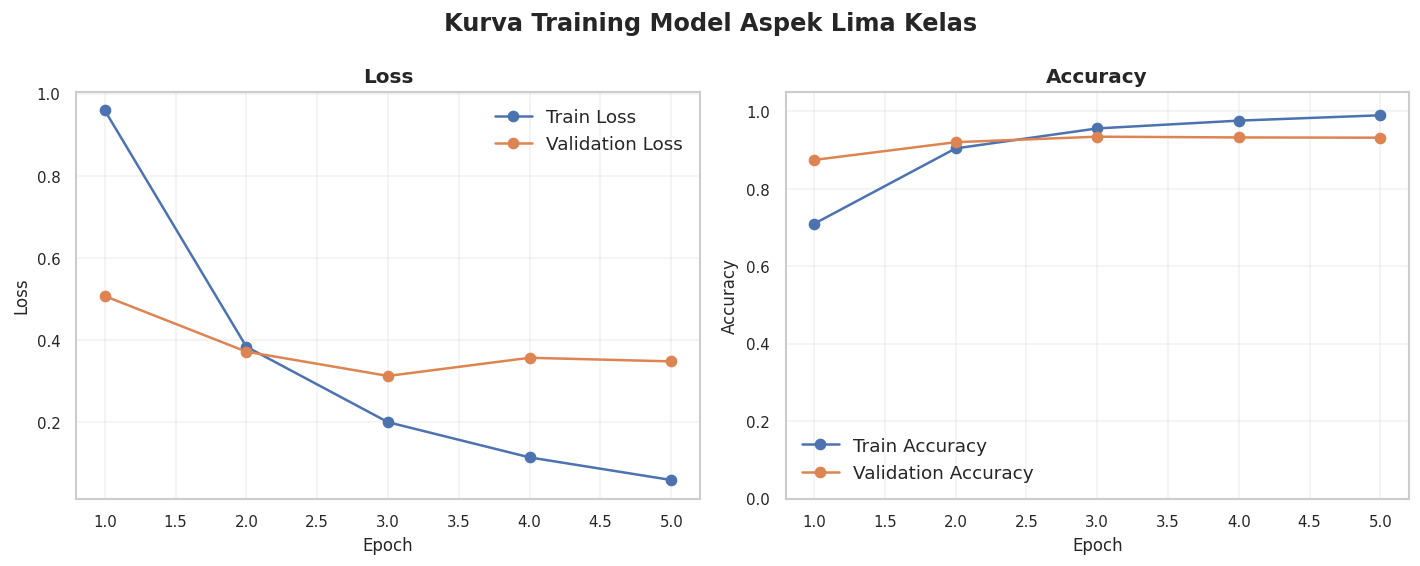

In [ ]:
# =========================================================
# 10. TRAINING DAN TUNING MODEL ASPEK LIMA KELAS
# =========================================================

train_aspect_y, aspect_label2id, aspect_id2label = encode_labels(
    train_aspect_df["aspect"],
    ASPECT_MODEL_LABELS,
)
val_aspect_y = [
    aspect_label2id[label] for label in val_df["aspect"]
]
test_aspect_y = [
    aspect_label2id[label] for label in test_df["aspect"]
]

aspect_model, aspect_history_all, aspect_tuning_results, aspect_best_config = (
    run_tuning(
        task_name="aspect_5_class",
        train_texts=train_aspect_df["review_clean"],
        train_labels=train_aspect_y,
        val_texts=val_df["review_clean"],
        val_labels=val_aspect_y,
        label_list=ASPECT_MODEL_LABELS,
    )
)

print("Best config aspek:")
display(pd.DataFrame([aspect_best_config]))

save_df(
    aspect_history_all,
    "08_aspect_training_history_all.xlsx",
)
save_df(
    aspect_tuning_results,
    "08_aspect_tuning_results.xlsx",
)
save_json(
    aspect_best_config,
    "08_aspect_best_config.json",
)

best_aspect_history = aspect_history_all[
    aspect_history_all["config_name"]
    == aspect_best_config["config_name"]
].copy()
plot_learning_curve(
    best_aspect_history,
    "Model Aspek Lima Kelas",
    "08_learning_curve_aspect",
)
plot_tuning_comparison(
    aspect_tuning_results,
    "Perbandingan Validation Macro F1 Model Aspek",
    "08_tuning_comparison_aspect.png",
)
render_dataframe_table(
    aspect_tuning_results,
    "Hasil Eksperimen Model Aspek",
    "08_tuning_results_aspect_table.png",
    columns=[
        "config_name",
        "lstm_layers",
        "lstm_hidden",
        "dropout",
        "learning_rate",
        "best_epoch",
        "val_acc",
        "val_macro_f1",
    ],
    max_rows=10,
)

torch.save({
    "model_state_dict": aspect_model.state_dict(),
    "label2id": aspect_label2id,
    "id2label": aspect_id2label,
    "best_config": aspect_best_config,
    "model_name": MODEL_NAME,
    "labels": ASPECT_MODEL_LABELS,
    "irrelevant_label": IRRELEVANT_ASPECT_LABEL,
    "architecture": "IndoBERT + packed BiLSTM",
}, MODEL_DIR / "aspect_indobert_bilstm_5class.pt")
print("Model aspek lima kelas tersimpan.")


## 9A. Contoh Eksekusi Model Aspek

Bagian ini memperlihatkan secara nyata bagaimana satu review diproses oleh model aspek:

`Review → Tokenizer → IndoBERT → BiLSTM → Dense → Softmax → Prediksi Aspek`

In [ ]:
# =========================================================
# 10A. TRACE EKSEKUSI MODEL ASPEK
# =========================================================

sample_aspect_text = (
    test_df["review_clean"].iloc[0]
    if len(test_df) > 0
    else train_aspect_df["review_clean"].iloc[0]
)

aspect_trace = trace_hybrid_model_execution(
    model=aspect_model,
    text=sample_aspect_text,
    label_list=ASPECT_MODEL_LABELS,
    max_len=int(aspect_best_config["max_len"]),
    title="Contoh Eksekusi Model Aspek Lima Kelas",
)

save_df(
    aspect_trace["token_df"],
    "08A_trace_aspect_tokenizer_output.xlsx",
)
save_df(
    aspect_trace["logits_df"],
    "08A_trace_aspect_logits.xlsx",
)
save_df(
    aspect_trace["probs_df"],
    "08A_trace_aspect_softmax_probability.xlsx",
)
save_json(
    aspect_trace["trace_summary"],
    "08A_trace_aspect_summary.json",
)


## 10. Training dan eksperimen model sentimen

Model sentimen hanya dilatih pada ulasan dengan empat aspek penelitian. Data berlabel `tidak_relevan` tidak dimasukkan karena tidak mempunyai target aspek substantif untuk dianalisis.

Input:

`aspek: <gold aspect>. ulasan: <review>`

Eksperimen tetap membandingkan BiLSTM 2, 3, dan 4 layer dengan *early stopping*.


In [ ]:
# =========================================================
# 11. TRAINING DAN TUNING MODEL SENTIMEN — DATA RELEVAN
# =========================================================

def make_sentiment_input(df, aspect_col="aspect"):
    return (
        "aspek: "
        + df[aspect_col].astype(str)
        + ". ulasan: "
        + df["review_clean"].astype(str)
    )


# Training sentiment sudah di-oversample terpisah pada Notebook Bagian 2.
train_sentiment_df = train_sentiment_df[
    train_sentiment_df["aspect"].isin(RESEARCH_ASPECT_LABELS)
].copy()

val_sentiment_df = val_df[
    val_df["aspect"].isin(RESEARCH_ASPECT_LABELS)
].copy()
test_sentiment_df = test_df[
    test_df["aspect"].isin(RESEARCH_ASPECT_LABELS)
].copy()

train_sentiment_df["sentiment_input_gold"] = make_sentiment_input(
    train_sentiment_df,
    "aspect",
)
val_sentiment_df["sentiment_input_gold"] = make_sentiment_input(
    val_sentiment_df,
    "aspect",
)
test_sentiment_df["sentiment_input_gold"] = make_sentiment_input(
    test_sentiment_df,
    "aspect",
)

model_input_audit = pd.DataFrame([
    {
        "model": "aspect",
        "input_column": "review_clean",
        "uses_rating": False,
        "rows": len(train_aspect_df),
    },
    {
        "model": "sentiment",
        "input_column": "sentiment_input_gold",
        "uses_rating": False,
        "rows": len(train_sentiment_df),
    },
])
display(model_input_audit)
save_df(
    model_input_audit,
    "09_model_input_audit_no_rating_feature.xlsx",
)

train_sentiment_y, sentiment_label2id, sentiment_id2label = encode_labels(
    train_sentiment_df["sentiment"],
    SENTIMENT_LABELS,
)
val_sentiment_y = [
    sentiment_label2id[label]
    for label in val_sentiment_df["sentiment"]
]
test_sentiment_y = [
    sentiment_label2id[label]
    for label in test_sentiment_df["sentiment"]
]

sentiment_model, sentiment_history_all, sentiment_tuning_results, sentiment_best_config = (
    run_tuning(
        task_name="sentiment_relevant_only",
        train_texts=train_sentiment_df["sentiment_input_gold"],
        train_labels=train_sentiment_y,
        val_texts=val_sentiment_df["sentiment_input_gold"],
        val_labels=val_sentiment_y,
        label_list=SENTIMENT_LABELS,
    )
)

print("Best config sentimen:")
display(pd.DataFrame([sentiment_best_config]))

save_df(
    sentiment_history_all,
    "09_sentiment_training_history_all.xlsx",
)
save_df(
    sentiment_tuning_results,
    "09_sentiment_tuning_results.xlsx",
)
save_json(
    sentiment_best_config,
    "09_sentiment_best_config.json",
)

best_sentiment_history = sentiment_history_all[
    sentiment_history_all["config_name"]
    == sentiment_best_config["config_name"]
].copy()
plot_learning_curve(
    best_sentiment_history,
    "Model Sentimen pada Ulasan Relevan",
    "09_learning_curve_sentiment",
)
plot_tuning_comparison(
    sentiment_tuning_results,
    "Perbandingan Validation Macro F1 Model Sentimen",
    "09_tuning_comparison_sentiment.png",
)
render_dataframe_table(
    sentiment_tuning_results,
    "Hasil Eksperimen Model Sentimen",
    "09_tuning_results_sentiment_table.png",
    columns=[
        "config_name",
        "lstm_layers",
        "lstm_hidden",
        "dropout",
        "learning_rate",
        "best_epoch",
        "val_acc",
        "val_macro_f1",
    ],
    max_rows=10,
)

torch.save({
    "model_state_dict": sentiment_model.state_dict(),
    "label2id": sentiment_label2id,
    "id2label": sentiment_id2label,
    "best_config": sentiment_best_config,
    "model_name": MODEL_NAME,
    "labels": SENTIMENT_LABELS,
    "research_aspects": RESEARCH_ASPECT_LABELS,
    "architecture": "IndoBERT + packed BiLSTM",
}, MODEL_DIR / "sentiment_indobert_bilstm_relevant.pt")
print("Model sentimen tersimpan.")


## 10A. Contoh Eksekusi Model Sentimen

Bagian ini memperlihatkan secara nyata bagaimana satu input sentimen diproses oleh model sentimen.

Input model sentimen memakai format:

`aspek: <aspek>. ulasan: <review>`

Tujuannya agar model sentimen mengetahui sentimen sedang dianalisis terhadap aspek apa.

In [ ]:
# =========================================================
# 11A. TRACE EKSEKUSI MODEL SENTIMEN
# =========================================================

sample_sentiment_text = (
    test_sentiment_df["sentiment_input_gold"].iloc[0]
    if len(test_sentiment_df) > 0
    else train_sentiment_df["sentiment_input_gold"].iloc[0]
)

sentiment_trace = trace_hybrid_model_execution(
    model=sentiment_model,
    text=sample_sentiment_text,
    label_list=SENTIMENT_LABELS,
    max_len=int(sentiment_best_config["max_len"]),
    title="Contoh Eksekusi Model Sentimen",
)

save_df(
    sentiment_trace["token_df"],
    "09A_trace_sentiment_tokenizer_output.xlsx",
)
save_df(
    sentiment_trace["logits_df"],
    "09A_trace_sentiment_logits.xlsx",
)
save_df(
    sentiment_trace["probs_df"],
    "09A_trace_sentiment_softmax_probability.xlsx",
)
save_json(
    sentiment_trace["trace_summary"],
    "09A_trace_sentiment_summary.json",
)


## 11. Evaluasi model pada test set

Evaluasi V5.4 terdiri dari:

1. **Model aspek lima kelas**, termasuk `tidak_relevan`.
2. **Model sentimen dengan gold aspect**, hanya pada ulasan relevan.
3. **Model sentimen pipeline kondisional**, yaitu ulasan relevan yang juga diprediksi relevan oleh model aspek. Nilai *coverage* dilaporkan agar kegagalan relevance gate tidak tersembunyi.
4. **Joint ABSA 13 kelas**:
   - satu kelas `tidak_relevan`;
   - dua belas kombinasi empat aspek × tiga sentimen.

Model terbaik tetap dipilih dari validation set, sedangkan test set hanya dipakai untuk evaluasi akhir.


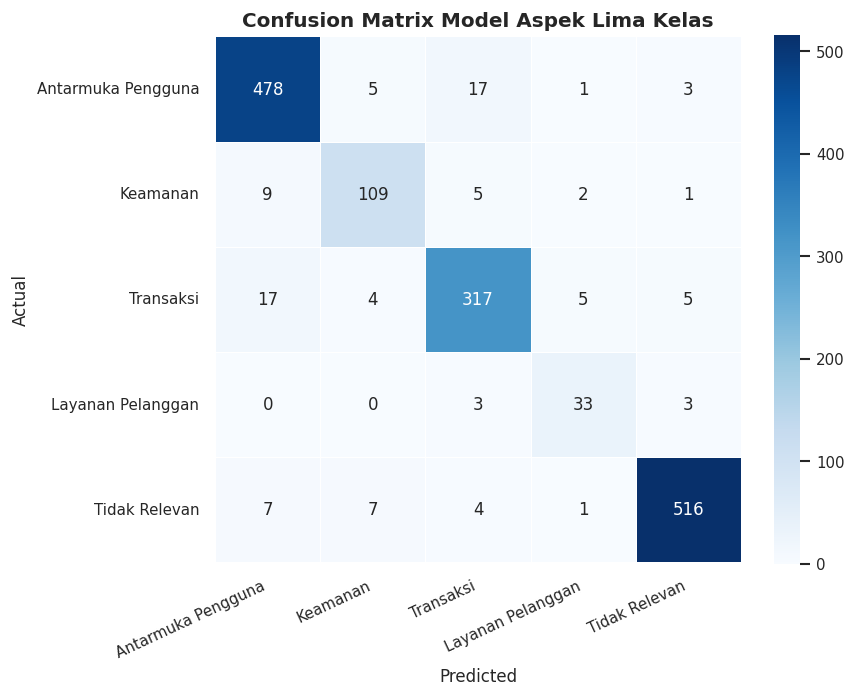

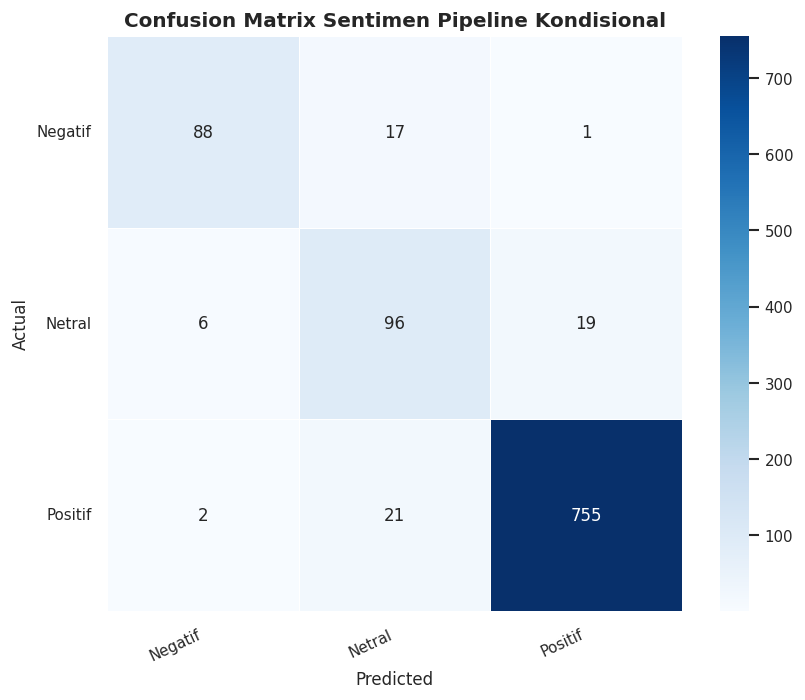

In [ ]:
# =========================================================
# 12. EVALUASI MODEL PADA TEST SET — 5 ASPECT / 13 JOINT
# =========================================================

test_eval_df = test_df.copy().reset_index(drop=True)

aspect_max_len = int(aspect_best_config["max_len"])
aspect_batch_size = int(aspect_best_config["batch_size"])
sentiment_max_len = int(sentiment_best_config["max_len"])
sentiment_batch_size = int(sentiment_best_config["batch_size"])

# ---------------------------------------------------------
# 1) MODEL ASPEK LIMA KELAS
# ---------------------------------------------------------
predicted_aspects, aspect_probabilities = predict_labels(
    aspect_model,
    test_eval_df["review_clean"],
    ASPECT_MODEL_LABELS,
    max_len=aspect_max_len,
    batch_size=aspect_batch_size,
)
test_eval_df["pred_aspect"] = predicted_aspects
test_eval_df["pred_aspect_confidence"] = aspect_probabilities.max(axis=1)

aspect_metrics = compute_metrics(
    test_eval_df["aspect"],
    test_eval_df["pred_aspect"],
)
print("METRICS MODEL ASPEK LIMA KELAS")
print(json.dumps(aspect_metrics, indent=2))

aspect_report_text = classification_report(
    test_eval_df["aspect"],
    test_eval_df["pred_aspect"],
    labels=ASPECT_MODEL_LABELS,
    zero_division=0,
)
print(aspect_report_text)

aspect_confusion_matrix = confusion_matrix(
    test_eval_df["aspect"],
    test_eval_df["pred_aspect"],
    labels=ASPECT_MODEL_LABELS,
)
plot_confusion_matrix(
    aspect_confusion_matrix,
    ASPECT_MODEL_LABELS,
    "Confusion Matrix Model Aspek Lima Kelas",
    "10_confusion_matrix_aspect_5class.png",
)

actual_relevant_mask = test_eval_df["aspect"].isin(
    RESEARCH_ASPECT_LABELS
)
predicted_relevant_mask = test_eval_df["pred_aspect"].isin(
    RESEARCH_ASPECT_LABELS
)

# ---------------------------------------------------------
# 2) SENTIMEN DENGAN GOLD ASPECT — RELEVAN SAJA
# ---------------------------------------------------------
test_eval_df["sentiment_input_gold"] = pd.NA
test_eval_df.loc[
    actual_relevant_mask,
    "sentiment_input_gold",
] = make_sentiment_input(
    test_eval_df.loc[actual_relevant_mask],
    "aspect",
)

predicted_sentiment_gold, sentiment_gold_probabilities = predict_labels(
    sentiment_model,
    test_eval_df.loc[
        actual_relevant_mask,
        "sentiment_input_gold",
    ],
    SENTIMENT_LABELS,
    max_len=sentiment_max_len,
    batch_size=sentiment_batch_size,
)

test_eval_df["pred_sentiment_gold_aspect"] = pd.NA
test_eval_df["pred_sentiment_gold_confidence"] = np.nan
test_eval_df.loc[
    actual_relevant_mask,
    "pred_sentiment_gold_aspect",
] = predicted_sentiment_gold
test_eval_df.loc[
    actual_relevant_mask,
    "pred_sentiment_gold_confidence",
] = sentiment_gold_probabilities.max(axis=1)

sentiment_gold_eval_df = test_eval_df.loc[
    actual_relevant_mask
].copy()
sentiment_metrics_gold = compute_metrics(
    sentiment_gold_eval_df["sentiment"],
    sentiment_gold_eval_df["pred_sentiment_gold_aspect"],
)

print("METRICS SENTIMEN DENGAN GOLD ASPECT")
print(json.dumps(sentiment_metrics_gold, indent=2))

sentiment_gold_report_text = classification_report(
    sentiment_gold_eval_df["sentiment"],
    sentiment_gold_eval_df["pred_sentiment_gold_aspect"],
    labels=SENTIMENT_LABELS,
    zero_division=0,
)
print(sentiment_gold_report_text)

sentiment_gold_confusion_matrix = confusion_matrix(
    sentiment_gold_eval_df["sentiment"],
    sentiment_gold_eval_df["pred_sentiment_gold_aspect"],
    labels=SENTIMENT_LABELS,
)
plot_confusion_matrix(
    sentiment_gold_confusion_matrix,
    SENTIMENT_LABELS,
    "Confusion Matrix Sentimen dengan Gold Aspect",
    "10_confusion_matrix_sentiment_gold_aspect.png",
)

# ---------------------------------------------------------
# 3) SENTIMEN PIPELINE — HANYA JIKA MODEL ASPEK RELEVAN
# ---------------------------------------------------------
test_eval_df["sentiment_input_pipeline"] = pd.NA
test_eval_df.loc[
    predicted_relevant_mask,
    "sentiment_input_pipeline",
] = (
    "aspek: "
    + test_eval_df.loc[
        predicted_relevant_mask,
        "pred_aspect",
    ].astype(str)
    + ". ulasan: "
    + test_eval_df.loc[
        predicted_relevant_mask,
        "review_clean",
    ].astype(str)
)

predicted_sentiment_pipeline, sentiment_pipeline_probabilities = (
    predict_labels(
        sentiment_model,
        test_eval_df.loc[
            predicted_relevant_mask,
            "sentiment_input_pipeline",
        ],
        SENTIMENT_LABELS,
        max_len=sentiment_max_len,
        batch_size=sentiment_batch_size,
    )
)

test_eval_df["pred_sentiment_pipeline"] = pd.NA
test_eval_df["pred_sentiment_pipeline_confidence"] = np.nan
test_eval_df.loc[
    predicted_relevant_mask,
    "pred_sentiment_pipeline",
] = predicted_sentiment_pipeline
test_eval_df.loc[
    predicted_relevant_mask,
    "pred_sentiment_pipeline_confidence",
] = sentiment_pipeline_probabilities.max(axis=1)

pipeline_eval_mask = actual_relevant_mask & predicted_relevant_mask
pipeline_eval_df = test_eval_df.loc[pipeline_eval_mask].copy()

pipeline_coverage = (
    len(pipeline_eval_df) / int(actual_relevant_mask.sum())
    if int(actual_relevant_mask.sum()) > 0
    else np.nan
)

if pipeline_eval_df.empty:
    sentiment_metrics_pipeline = compute_metrics([], [])
    sentiment_pipeline_report_text = (
        "Tidak ada ulasan relevan yang diprediksi relevan oleh model aspek; "
        "evaluasi sentimen pipeline kondisional tidak dapat dihitung."
    )
    sentiment_pipeline_confusion_matrix = np.zeros(
        (len(SENTIMENT_LABELS), len(SENTIMENT_LABELS)),
        dtype=int,
    )
else:
    sentiment_metrics_pipeline = compute_metrics(
        pipeline_eval_df["sentiment"],
        pipeline_eval_df["pred_sentiment_pipeline"],
    )
    sentiment_pipeline_report_text = classification_report(
        pipeline_eval_df["sentiment"],
        pipeline_eval_df["pred_sentiment_pipeline"],
        labels=SENTIMENT_LABELS,
        zero_division=0,
    )
    sentiment_pipeline_confusion_matrix = confusion_matrix(
        pipeline_eval_df["sentiment"],
        pipeline_eval_df["pred_sentiment_pipeline"],
        labels=SENTIMENT_LABELS,
    )

print("METRICS SENTIMEN PIPELINE KONDISIONAL")
print(json.dumps(sentiment_metrics_pipeline, indent=2))
print("Pipeline coverage terhadap data relevan:", pipeline_coverage)
print(sentiment_pipeline_report_text)

plot_confusion_matrix(
    sentiment_pipeline_confusion_matrix,
    SENTIMENT_LABELS,
    "Confusion Matrix Sentimen Pipeline Kondisional",
    "10_confusion_matrix_sentiment_pipeline_conditional.png",
)

# ---------------------------------------------------------
# 4) JOINT ABSA 13 KELAS END-TO-END
# ---------------------------------------------------------
test_eval_df["joint_actual"] = np.where(
    test_eval_df["aspect"] == IRRELEVANT_ASPECT_LABEL,
    IRRELEVANT_ASPECT_LABEL,
    test_eval_df["aspect"].astype(str)
    + "__"
    + test_eval_df["sentiment"].astype(str),
)
test_eval_df["joint_pred"] = np.where(
    test_eval_df["pred_aspect"] == IRRELEVANT_ASPECT_LABEL,
    IRRELEVANT_ASPECT_LABEL,
    test_eval_df["pred_aspect"].astype(str)
    + "__"
    + test_eval_df["pred_sentiment_pipeline"].astype(str),
)
test_eval_df["joint_correct"] = (
    test_eval_df["joint_actual"] == test_eval_df["joint_pred"]
)

JOINT_LABELS = [IRRELEVANT_ASPECT_LABEL] + [
    f"{aspect}__{sentiment}"
    for aspect in RESEARCH_ASPECT_LABELS
    for sentiment in SENTIMENT_LABELS
]

joint_metrics = compute_metrics(
    test_eval_df["joint_actual"],
    test_eval_df["joint_pred"],
)
print("METRICS JOINT ABSA 13 KELAS")
print(json.dumps(joint_metrics, indent=2))

joint_report_text = classification_report(
    test_eval_df["joint_actual"],
    test_eval_df["joint_pred"],
    labels=JOINT_LABELS,
    zero_division=0,
)
print(joint_report_text)

joint_confusion_matrix = confusion_matrix(
    test_eval_df["joint_actual"],
    test_eval_df["joint_pred"],
    labels=JOINT_LABELS,
)
plot_confusion_matrix(
    joint_confusion_matrix,
    JOINT_LABELS,
    "Confusion Matrix Joint ABSA 13 Kelas",
    "10_confusion_matrix_joint_absa_13class.png",
)

metrics_summary = pd.DataFrame([
    {
        "evaluation": "aspect_model_5_class",
        "evaluation_rows": len(test_eval_df),
        "coverage": 1.0,
        **aspect_metrics,
    },
    {
        "evaluation": "sentiment_model_gold_aspect_relevant_only",
        "evaluation_rows": len(sentiment_gold_eval_df),
        "coverage": 1.0,
        **sentiment_metrics_gold,
    },
    {
        "evaluation": "sentiment_pipeline_conditional",
        "evaluation_rows": len(pipeline_eval_df),
        "coverage": pipeline_coverage,
        **sentiment_metrics_pipeline,
    },
    {
        "evaluation": "joint_absa_end_to_end_13_class",
        "evaluation_rows": len(test_eval_df),
        "coverage": 1.0,
        **joint_metrics,
    },
])
display(metrics_summary)
save_df(metrics_summary, "10_metrics_summary.xlsx")
save_df(test_eval_df, "10_test_predictions_detail.xlsx")

# Reports sebagai tabel.
aspect_report_df = pd.DataFrame(
    classification_report(
        test_eval_df["aspect"],
        test_eval_df["pred_aspect"],
        labels=ASPECT_MODEL_LABELS,
        zero_division=0,
        output_dict=True,
    )
).T.reset_index().rename(columns={"index": "label"})

sentiment_gold_report_df = pd.DataFrame(
    classification_report(
        sentiment_gold_eval_df["sentiment"],
        sentiment_gold_eval_df["pred_sentiment_gold_aspect"],
        labels=SENTIMENT_LABELS,
        zero_division=0,
        output_dict=True,
    )
).T.reset_index().rename(columns={"index": "label"})

if pipeline_eval_df.empty:
    sentiment_pipeline_report_df = pd.DataFrame([
        {
            "label": "no_pipeline_coverage",
            "precision": np.nan,
            "recall": np.nan,
            "f1-score": np.nan,
            "support": 0,
        }
    ])
else:
    sentiment_pipeline_report_df = pd.DataFrame(
        classification_report(
            pipeline_eval_df["sentiment"],
            pipeline_eval_df["pred_sentiment_pipeline"],
            labels=SENTIMENT_LABELS,
            zero_division=0,
            output_dict=True,
        )
    ).T.reset_index().rename(columns={"index": "label"})

joint_report_df = pd.DataFrame(
    classification_report(
        test_eval_df["joint_actual"],
        test_eval_df["joint_pred"],
        labels=JOINT_LABELS,
        zero_division=0,
        output_dict=True,
    )
).T.reset_index().rename(columns={"index": "label"})

save_df(aspect_report_df, "10_classification_report_aspect_5class.xlsx")
save_df(
    sentiment_gold_report_df,
    "10_classification_report_sentiment_gold_aspect.xlsx",
)
save_df(
    sentiment_pipeline_report_df,
    "10_classification_report_sentiment_pipeline_conditional.xlsx",
)
save_df(
    joint_report_df,
    "10_classification_report_joint_absa_13class.xlsx",
)

# ---------------------------------------------------------
# VISUALISASI EVALUASI GAYA FELIA
# ---------------------------------------------------------
plot_confusion_matrix_with_report(
    aspect_confusion_matrix,
    ASPECT_MODEL_LABELS,
    aspect_report_df,
    "Model Aspek Lima Kelas",
    "10_evaluation_aspect_cm_and_report.png",
)
plot_confusion_matrix_with_report(
    sentiment_gold_confusion_matrix,
    SENTIMENT_LABELS,
    sentiment_gold_report_df,
    "Sentimen dengan Gold Aspect",
    "10_evaluation_sentiment_gold_cm_and_report.png",
)
if not pipeline_eval_df.empty:
    plot_confusion_matrix_with_report(
        sentiment_pipeline_confusion_matrix,
        SENTIMENT_LABELS,
        sentiment_pipeline_report_df,
        "Sentimen Pipeline Kondisional",
        "10_evaluation_sentiment_pipeline_cm_and_report.png",
    )

render_dataframe_table(
    metrics_summary,
    "Ringkasan Metrik Evaluasi Model",
    "10_metrics_summary_table.png",
    columns=[
        "evaluation",
        "evaluation_rows",
        "coverage",
        "accuracy",
        "macro_precision",
        "macro_recall",
        "macro_f1",
    ],
    max_rows=10,
)
render_dataframe_table(
    joint_report_df,
    "Classification Report Joint ABSA 13 Kelas",
    "10_joint_absa_classification_report_table.png",
    columns=[
        "label",
        "precision",
        "recall",
        "f1-score",
        "support",
    ],
    max_rows=20,
)

with open(
    OUT_DIR / "10_classification_reports.txt",
    "w",
    encoding="utf-8",
) as file:
    file.write("=== MODEL ASPEK LIMA KELAS ===\n")
    file.write(aspect_report_text)
    file.write("\n\n=== SENTIMEN GOLD ASPECT — RELEVAN SAJA ===\n")
    file.write(sentiment_gold_report_text)
    file.write("\n\n=== SENTIMEN PIPELINE KONDISIONAL ===\n")
    file.write(sentiment_pipeline_report_text)
    file.write("\n\n=== JOINT ABSA 13 KELAS ===\n")
    file.write(joint_report_text)

joint_support_df = (
    test_eval_df["joint_actual"]
    .value_counts()
    .reindex(JOINT_LABELS, fill_value=0)
    .rename_axis("joint_label")
    .reset_index(name="test_support")
)
joint_support_df["low_support_warning"] = (
    joint_support_df["test_support"] < LOW_SUPPORT_THRESHOLD
)
display(joint_support_df)
save_df(
    joint_support_df,
    "10_joint_label_test_support_audit.xlsx",
)

test_size_audit_df = pd.DataFrame([{
    "test_rows": len(test_eval_df),
    "relevant_test_rows": int(actual_relevant_mask.sum()),
    "irrelevant_test_rows": int((~actual_relevant_mask).sum()),
    "pipeline_relevant_rows": len(pipeline_eval_df),
    "pipeline_coverage": pipeline_coverage,
    "minimum_support_warning_threshold": LOW_SUPPORT_THRESHOLD,
    "near_duplicate_group_overlap": int(
        group_split_overlap_audit_df["overlap_group_count"].sum()
    ),
}])
display(test_size_audit_df)
save_df(test_size_audit_df, "10_test_size_audit.xlsx")


## 12. Evaluasi sentimen dan Joint ABSA per aspek

Evaluasi per aspek hanya dilakukan pada empat aspek substantif. `tidak_relevan` dilaporkan pada evaluasi model aspek dan Joint ABSA 13 kelas, tetapi tidak mempunyai evaluasi sentimen per aspek.


In [ ]:
# =========================================================
# 13. EVALUASI SENTIMEN DAN JOINT ABSA PER ASPEK
# =========================================================

per_aspect_rows = []

for aspect_name in RESEARCH_ASPECT_LABELS:
    subset = test_eval_df[
        test_eval_df["aspect"] == aspect_name
    ].copy()
    if subset.empty:
        continue

    gold_metrics = compute_metrics(
        subset["sentiment"],
        subset["pred_sentiment_gold_aspect"],
    )

    pipeline_subset = subset[
        subset["pred_aspect"].isin(RESEARCH_ASPECT_LABELS)
    ].copy()
    pipeline_metrics = compute_metrics(
        pipeline_subset["sentiment"],
        pipeline_subset["pred_sentiment_pipeline"],
    )
    pipeline_aspect_coverage = (
        len(pipeline_subset) / len(subset)
        if len(subset) > 0
        else np.nan
    )

    aspect_accuracy = accuracy_score(
        subset["aspect"],
        subset["pred_aspect"],
    )
    joint_metrics_for_aspect = compute_metrics(
        subset["joint_actual"],
        subset["joint_pred"],
    )

    sentiment_support = (
        subset["sentiment"]
        .value_counts()
        .reindex(SENTIMENT_LABELS, fill_value=0)
    )
    minimum_sentiment_support = int(sentiment_support.min())

    per_aspect_rows.append({
        "aspect": aspect_name,
        "support": len(subset),
        "minimum_sentiment_class_support": minimum_sentiment_support,
        "low_support_warning": (
            minimum_sentiment_support < LOW_SUPPORT_THRESHOLD
        ),
        "aspect_accuracy": aspect_accuracy,
        "sentiment_accuracy_gold_aspect": gold_metrics["accuracy"],
        "sentiment_macro_f1_gold_aspect": gold_metrics["macro_f1"],
        "sentiment_pipeline_coverage": pipeline_aspect_coverage,
        "sentiment_accuracy_pipeline_conditional": (
            pipeline_metrics["accuracy"]
        ),
        "sentiment_macro_f1_pipeline_conditional": (
            pipeline_metrics["macro_f1"]
        ),
        "joint_absa_accuracy": joint_metrics_for_aspect["accuracy"],
        "joint_absa_macro_precision": (
            joint_metrics_for_aspect["macro_precision"]
        ),
        "joint_absa_macro_recall": (
            joint_metrics_for_aspect["macro_recall"]
        ),
        "joint_absa_macro_f1": (
            joint_metrics_for_aspect["macro_f1"]
        ),
    })

per_aspect_eval_df = pd.DataFrame(per_aspect_rows)
display(per_aspect_eval_df)
save_df(
    per_aspect_eval_df,
    "10_per_aspect_sentiment_evaluation.xlsx",
)
# Alias lama tetap disimpan agar kompatibel dengan kode sebelumnya.
save_df(
    per_aspect_eval_df,
    "10_per_aspect_evaluation.xlsx",
)

if not per_aspect_eval_df.empty:
    plt.figure(figsize=(9, 5))
    plt.bar(
        per_aspect_eval_df["aspect"],
        per_aspect_eval_df["joint_absa_accuracy"],
    )
    plt.title("Joint ABSA Accuracy per Aspek")
    plt.xlabel("Aspek")
    plt.ylabel("Joint ABSA Accuracy")
    plt.xticks(rotation=30, ha="right")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.savefig(
        FIG_DIR / "10_joint_absa_accuracy_per_aspect.png",
        dpi=200,
        bbox_inches="tight",
    )
    plt.show()

with pd.ExcelWriter(
    OUT_DIR / "10_confusion_matrix_sentiment_per_aspect.xlsx"
) as writer:
    for aspect_name in RESEARCH_ASPECT_LABELS:
        subset = test_eval_df[
            (test_eval_df["aspect"] == aspect_name)
            & test_eval_df["pred_aspect"].isin(RESEARCH_ASPECT_LABELS)
        ].copy()
        if subset.empty:
            continue

        matrix = confusion_matrix(
            subset["sentiment"],
            subset["pred_sentiment_pipeline"],
            labels=SENTIMENT_LABELS,
        )
        matrix_df = pd.DataFrame(
            matrix,
            index=SENTIMENT_LABELS,
            columns=SENTIMENT_LABELS,
        )
        matrix_df.to_excel(
            writer,
            sheet_name=aspect_name[:31],
        )
        plot_confusion_matrix(
            matrix,
            SENTIMENT_LABELS,
            f"Confusion Matrix Sentimen Pipeline - {aspect_name}",
            f"10_cm_sentiment_pipeline_{aspect_name}.png",
        )

per_aspect_sentiment_support_df = (
    test_eval_df[
        test_eval_df["aspect"].isin(RESEARCH_ASPECT_LABELS)
    ]
    .groupby(["aspect", "sentiment"])
    .size()
    .reindex(
        pd.MultiIndex.from_product(
            [RESEARCH_ASPECT_LABELS, SENTIMENT_LABELS],
            names=["aspect", "sentiment"],
        ),
        fill_value=0,
    )
    .rename("test_support")
    .reset_index()
)
per_aspect_sentiment_support_df["low_support_warning"] = (
    per_aspect_sentiment_support_df["test_support"]
    < LOW_SUPPORT_THRESHOLD
)
display(per_aspect_sentiment_support_df)
save_df(
    per_aspect_sentiment_support_df,
    "10_per_aspect_sentiment_test_support_audit.xlsx",
)


# ---------------------------------------------------------
# VISUALISASI PER ASPEK: CM + CLASSIFICATION REPORT
# ---------------------------------------------------------
per_aspect_report_path = (
    OUT_DIR / "10_classification_report_sentiment_per_aspect.xlsx"
)
with pd.ExcelWriter(per_aspect_report_path) as report_writer:
    for aspect_name in RESEARCH_ASPECT_LABELS:
        subset = test_eval_df[
            (test_eval_df["aspect"] == aspect_name)
            & test_eval_df["pred_aspect"].isin(RESEARCH_ASPECT_LABELS)
        ].copy()
        if subset.empty:
            continue

        report_df = pd.DataFrame(
            classification_report(
                subset["sentiment"],
                subset["pred_sentiment_pipeline"],
                labels=SENTIMENT_LABELS,
                zero_division=0,
                output_dict=True,
            )
        ).T.reset_index().rename(columns={"index": "label"})

        report_df.to_excel(
            report_writer,
            sheet_name=aspect_name[:31],
            index=False,
        )

        matrix = confusion_matrix(
            subset["sentiment"],
            subset["pred_sentiment_pipeline"],
            labels=SENTIMENT_LABELS,
        )
        plot_confusion_matrix_with_report(
            matrix,
            SENTIMENT_LABELS,
            report_df,
            pretty_label(aspect_name),
            f"10_evaluation_sentiment_{aspect_name}_cm_and_report.png",
        )

render_dataframe_table(
    per_aspect_eval_df,
    "Evaluasi Model per Aspek",
    "10_per_aspect_evaluation_table.png",
    columns=[
        "aspect",
        "support",
        "aspect_accuracy",
        "sentiment_accuracy_gold_aspect",
        "sentiment_macro_f1_gold_aspect",
        "sentiment_pipeline_coverage",
        "sentiment_accuracy_pipeline_conditional",
        "sentiment_macro_f1_pipeline_conditional",
        "joint_absa_accuracy",
        "joint_absa_macro_f1",
    ],
    max_rows=10,
)
print("Saved:", per_aspect_report_path)


## Checkpoint Fase 3

Model terbaik, konfigurasi eksperimen, hasil evaluasi data uji, dan seluruh artefak Fase 3 disimpan agar Fase 4 dapat dijalankan tanpa melatih model ulang.


## Indeks Output BAB IV

Cell berikut membuat manifest ringkas berisi tabel dan gambar utama bergaya Felia. Manifest ini memudahkan pemilihan gambar yang akan dimasukkan ke laporan.


In [ ]:
# =========================================================
# INDEKS OUTPUT BAB IV
# =========================================================

bab4_output_rows = []

for path in sorted(FELIA_STYLE_DIR.glob("*.png")):
    bab4_output_rows.append({
        "jenis": "gambar",
        "nama_file": path.name,
        "lokasi": str(path),
    })

for path in sorted(BAB4_TABLE_DIR.glob("*.xlsx")):
    bab4_output_rows.append({
        "jenis": "tabel",
        "nama_file": path.name,
        "lokasi": str(path),
    })

bab4_output_manifest = pd.DataFrame(bab4_output_rows)
display(bab4_output_manifest)
bab4_output_manifest.to_excel(
    OUT_DIR / "BAB4_FELIA_STYLE_OUTPUT_MANIFEST.xlsx",
    index=False,
)
print("Jumlah output BAB IV:", len(bab4_output_manifest))


In [ ]:
# =========================================================
# CHECKPOINT FASE 3 — MODEL DAN EVALUASI TERVERIFIKASI
# =========================================================
import zipfile
# Final safety check sebelum checkpoint dibungkus.
if run_config.get("annotation_provenance") != "manual_human":
    raise RuntimeError("Checkpoint Fase 3 ditolak: annotation_provenance bukan manual_human.")
if run_config.get("final_research_run") is not True:
    raise RuntimeError("Checkpoint Fase 3 ditolak: final_research_run bukan True.")

required_stage3_files=[
 OUT_DIR/"00_run_config.json",OUT_DIR/"06_annotation_provenance.json",
 MODEL_DIR/"aspect_indobert_bilstm_5class.pt",MODEL_DIR/"sentiment_indobert_bilstm_relevant.pt",
 OUT_DIR/"08_aspect_training_history_all.xlsx",OUT_DIR/"08_aspect_tuning_results.xlsx",OUT_DIR/"08_aspect_best_config.json",
 OUT_DIR/"09_sentiment_training_history_all.xlsx",OUT_DIR/"09_sentiment_tuning_results.xlsx",OUT_DIR/"09_sentiment_best_config.json",
 OUT_DIR/"10_metrics_summary.xlsx",OUT_DIR/"10_test_predictions_detail.xlsx",OUT_DIR/"10_classification_report_aspect_5class.xlsx",
 OUT_DIR/"10_classification_report_sentiment_gold_aspect.xlsx",OUT_DIR/"10_classification_report_sentiment_pipeline_conditional.xlsx",
 OUT_DIR/"10_classification_report_joint_absa_13class.xlsx",OUT_DIR/"10_joint_label_test_support_audit.xlsx",
 OUT_DIR/"10_per_aspect_sentiment_test_support_audit.xlsx",OUT_DIR/"10_per_aspect_sentiment_evaluation.xlsx"]
rows=[]
for p in required_stage3_files: rows.append({'path':str(p.relative_to(STAGE3_DIR)),'status':'exists' if p.is_file() else 'missing','size_mb':round(p.stat().st_size/1024**2,4) if p.is_file() else np.nan})
stage3_manifest=pd.DataFrame(rows); display(stage3_manifest); stage3_manifest.to_excel(STAGE3_DIR/"STAGE3_MANIFEST.xlsx",index=False)
missing=stage3_manifest.loc[stage3_manifest.status=='missing','path'].tolist()
if missing: raise FileNotFoundError("Checkpoint Fase 3 belum lengkap: "+', '.join(missing))
# =========================================================
# VALIDASI UKURAN FILE MODEL SAJA
# =========================================================

model_files = [
    MODEL_DIR / "aspect_indobert_bilstm_5class.pt",
    MODEL_DIR / "sentiment_indobert_bilstm_relevant.pt",
]

for p in model_files:
    if not p.is_file():
        raise FileNotFoundError(f"Model tidak ditemukan: {p}")

    size_mb = p.stat().st_size / (1024 ** 2)

    if p.stat().st_size < 50 * 1024 * 1024:
        raise RuntimeError(
            f"Ukuran model tidak wajar: {p} ({size_mb:.2f} MB)"
        )

    print(f"✅ Model valid: {p.name} — {size_mb:.2f} MB")
tmp=Path('/content/stage3_checkpoint_v5_4_verified'); tmp.with_suffix('.zip').unlink(missing_ok=True)
created=Path(shutil.make_archive(str(tmp),'zip',root_dir=STAGE3_DIR))
if not zipfile.is_zipfile(created): raise RuntimeError("ZIP lokal tidak valid")
with zipfile.ZipFile(created,'r') as a: bad=a.testzip()
if bad is not None: raise RuntimeError(f"ZIP lokal rusak: {bad}")
final=PROJECT_DIR/"stage3_checkpoint_v5_4.zip"; shutil.copy2(created,final)
if not zipfile.is_zipfile(final): raise RuntimeError("ZIP Drive tidak valid")
with zipfile.ZipFile(final,'r') as a: bad=a.testzip()
if bad is not None: raise RuntimeError(f"ZIP Drive rusak: {bad}")
created.unlink(missing_ok=True)
print("Checkpoint Fase 3 valid:",final)
print("Fase 4 dapat dijalankan tanpa training ulang.")
